# Compressive Sensing for Scattered Light Imaging (SLI): A Practical Tutorial

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dscheidt567/From-single-pixel-imaging-to-scattered-light-imaging-A-practical-tutorial/blob/main/Tutorial_CS_SLI.ipynb)

**Notebook and data:** [GitHub repository](https://github.com/dscheidt567/From-single-pixel-imaging-to-scattered-light-imaging-A-practical-tutorial) · [Processing data on Zenodo](https://doi.org/10.5281/zenodo.23825919) · **[Accompanying manuscript (DOI link to be added)](https://doi.org/REPLACE_WITH_MANUSCRIPT_DOI)**

This notebook accompanies the tutorial manuscript. It applies single-pixel imaging (SPI) and compressive sensing (CS) to **Scattered Light Imaging (SLI)** using **experimentally measured angular line profiles** from a crossing-fibre phantom.

**Why SLI can be treated as a single-pixel problem.** In SLI the sample is illuminated sequentially from $N$ azimuthal directions (segments of an LED display), and a camera records the scattered light. Every camera pixel therefore records an angular *line profile* $z(\varphi_j)$, $j = 0,\dots,N-1$, whose peaks contain information about local fibre directions. If, instead of one segment at a time (canonical basis), several segments are switched on together according to a Hadamard pattern, each camera pixel integrates light from many directions at once. Each camera pixel then acts as a **bucket detector** for its angular profile, so many single-pixel measurements are recorded in parallel.

**Notation used throughout** (it is identical in the manuscript):

| Symbol | Meaning |
|---|---|
| $N$ | number of illumination segments = number of angular samples of a line profile = number of patterns in a complete basis ($N = 16, 32, 64$) |
| $M$ | number of patterns that are actually used ($M \le N$) |
| $\mathrm{CR} = M/N$ | compression ratio (fraction of measurements kept) |
| $z \in \mathbb{R}^N$ | angular line profile of one pixel or ROI (the unknown) |
| $\Phi \in \mathbb{R}^{M\times N}$ | measurement matrix (usually the first $M$ rows of an ordered, orthonormal Hadamard matrix) |
| $y = \Phi G z$ | measurement vector |
| $G$ | diagonal calibration matrix (segment gains); $G = I$ for an ideal system and for the offset correction used here |
| $\Psi \in \mathbb{R}^{N\times N}$ | sparsifying basis; **always the orthonormal inverse DCT in this notebook** |
| $s$ | sparse coefficients, $z = \Psi s$; $\Theta = \Phi G \Psi$ |

**Navigate to a section** (links open the corresponding cell in Google Colab):

0. [Setup](#scrollTo=0f5568b6) — [0.1 Data configuration](#scrollTo=f73d8482) · [0.2 Finding the data](#scrollTo=3c335c5c) · [0.3 Overview and ROIs](#scrollTo=ed335cdf)
1. [Full-basis sampling: canonical vs Hadamard SLI](#scrollTo=b243d8fd)
2. [Sparsity and incoherence](#scrollTo=0c4e2bc8)
3. [Hadamard ordering](#scrollTo=03d3a406) — [3.1 Solvers and metrics](#scrollTo=49efa09f) · [3.2 Ordering study](#scrollTo=b42bf2c7) · [3.3 Plateau](#scrollTo=b3ead444) · [3.4 Reconstruction profiles](#scrollTo=ff310a2b)
4. [Reconstruction algorithms](#scrollTo=61b987f3)
5. [Noise robustness (diagnostic)](#scrollTo=0a48ce9b)
6. [Learned linear reconstruction](#scrollTo=825cdb22)
7. [Direction maps](#scrollTo=c7fbcbf5) — [7.1 Reconstruction time](#scrollTo=273feac5)
8. [Summary and exercises](#scrollTo=989fa0e0)


## 0. Setup

The notebook uses three groups of code:

* **Packages:** `spgl1` provides the basis-pursuit solvers, `tifffile` reads the raw SLI frames, PyTorch (preinstalled on Colab) is used in [Section 6](#scrollTo=825cdb22).
* **`sli_helpers.py`:** generic helper functions that are not specific to single-pixel imaging or compressive sensing: reading the TIFF frames, selecting regions of interest, metrics, figure styles, plotting and saving the results. It is part of the GitHub repository together with **`sli_data.py`**, which downloads the measurement data on first use.
* **This notebook:** everything that belongs to single-pixel imaging and compressive sensing (Hadamard sampling, offset correction, sparsity, orderings, solvers, learned reconstruction) is defined and commented directly in the cells where it is used.

**Run time.** The first line of every code cell gives its approximate run time on a standard Colab CPU runtime with the full data set; the quick run ([Section 0.1](#scrollTo=f73d8482)) skips the reading of the raw frames. After each cell that takes longer than a few seconds, the measured run time is printed. Reading the raw frames dominates the first sections. The frames are cached in memory, so every frame is read only once per session. The analysis takes about 20–25 minutes in the full-run configuration, excluding the initial download.

In [1]:
# ⏱ < 30 s (first run only)
import importlib, subprocess, sys
for pkg in ["spgl1", "tifffile"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

In [2]:
# ⏱ ~20 s
import os, sys, subprocess

REPO_URL = "https://github.com/dscheidt567/From-single-pixel-imaging-to-scattered-light-imaging-A-practical-tutorial.git"
if "google.colab" in sys.modules:          # Colab: get sli_helpers.py and sli_data.py from the repository
    CODE_DIR = "/content/sli_tutorial"
    if not os.path.exists(CODE_DIR):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, CODE_DIR], check=True)
else:                                      # local: start the notebook from the repository folder
    CODE_DIR = os.getcwd()
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
for f in ("sli_helpers.py", "sli_data.py"):
    if not os.path.exists(os.path.join(CODE_DIR, f)):
        raise FileNotFoundError(f"{f} not found in {CODE_DIR}. Start the notebook from the repository folder.")

In [3]:
# ⏱ ~5 s
import re, time, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spgl1
from scipy.linalg import hadamard
from scipy.fft import idct, dct

import sli_data
import sli_helpers as sh
from sli_helpers import (                     # generic helpers used throughout the notebook
    configure, init_output, savefig, save_table, enable_cell_timer,
    discover_stacks, frame_files, read_frame, load_binned_stack, load_roi_profiles, load_stack_and_rois,
    physical_angles, prepare_profile_for_plot,
    ncc, rmse, ncc_rows, nanmean_quiet, axial_difference, match_affine,
    classify_regions, auto_rois, format_duration,
    COLORS, ALG_COLORS,
)

try:
    import torch
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

plt.rcParams.update(sh.NOTEBOOK_RC)   # diagnostic figures; article figures use sh.ARTICLE_RC
enable_cell_timer()                  # prints the run time below every cell that takes > 2 s
print("PyTorch available:", HAS_TORCH)

PyTorch available: True


### 0.1 Data configuration

**Quick run or full run.** With `QUICK_RUN = True` (default), the notebook does not read the raw frames (about 6 GB). Instead, it uses a recording of the data required for the analysis: the $43\times43$ binned stacks, the full-resolution data of the four $100\times100$ px ROIs, and the profiles of the calibration region. Data requests are served from this recording, so all figures and tables are reproduced as in the full run. The quick dataset covers exactly these settings: changing the ROIs, `ROI_SIZE`, or `PREVIEW_BIN` requires the full dataset (`QUICK_RUN = False`). A message indicates if a cell requests data that is not included in the recording. All other parameters (orderings, solvers, noise levels, training settings, and the exercises in [Section 8](#scrollTo=989fa0e0)) can be changed freely. A full run requires downloading the [original data from Zenodo](https://doi.org/10.5281/zenodo.23825919), which may take 30–60 minutes depending on the internet connection. Since Colab can disconnect during an extended download, the full run is recommended on a local machine. It can also be performed in Colab, but may require periodic interaction to keep the session active. **Quick run is therefore the default.**

Both data sets are downloaded automatically on first use (`sli_data.py`) and reused afterwards. If you already have a copy of the data, set the environment variable `SLI_DATA_ROOT` (folder with the raw frames) or `SLI_QUICK_ROOT` (folder or `sli_quick.zip`) before running the cell below, and nothing is downloaded.

The raw data are individual TIFF frames, one per illumination pattern, for $N = 16, 32, 64$ and for the canonical (`can`) and Hadamard (`had`) bases. The loader expects folder names that contain the basis and $N$, e.g.

```
<DATA_ROOT>/can_32/*.tiff
<DATA_ROOT>/had_32/*.tiff
```

The folders are found automatically below `DATA_ROOT` (sub-folders such as `X01Y01` are allowed). If your layout differs, fill in `DATA_DIRS` by hand. Each folder must hold exactly the $N$ frames of the basis; if an additional frame is stored first, set `SKIP_FIRST_FRAME = True` (or `"auto"`). For the Hadamard data, frame $k$ corresponds to row $k$ of the **natural-ordered** binary Hadamard matrix $H^+ = (H+1)/2$, so the first frame is the all-segments-on pattern.

Results are written to `OUTPUT_DIR` (`results/` or, for a quick run, `results_quick/` in `CODE_DIR`; in Colab this folder is deleted with the runtime, so download it if you want to keep the results), separated into `article` (figures and tables for the manuscript) and `diagnostics` (checks and intermediate results).

In [ ]:
# ⏱ < 1 s (plus a one-time download of the data)
# IMPORTANT loading the full dataset (QUICK_RUN = False) might take 30-60 minutes. It is recommended for a local machine as colab might disconnect due to inactivity
# ---------------------------------------------------------------- paths
QUICK_RUN = True           # True: recorded data of the published run (small, fast); False: full raw data (~6 GB)

DATA_ROOT = sli_data.get_data(quick=QUICK_RUN)          # downloads once, then reuses the local copy
QUICK = sli_data.quick_meta(DATA_ROOT)                   # description of the quick data set, None for the raw data
if QUICK:
    sli_data.install_replay(globals(), sh, DATA_ROOT)    # the data loaders answer from the recorded data
OUTPUT_DIR = Path(os.environ.get("SLI_OUTPUT_DIR", os.path.join(CODE_DIR, "results_quick" if QUICK else "results")))
DATA_DIRS = {}              # optional manual override: {("can", 32): "/path/to/tiffs", ...}

# ---------------------------------------------------------------- acquisition
NS = [16, 32, 64]
SKIP_FIRST_FRAME = False    # True: skip the first TIFF, "auto": skip it only if a folder holds N+1 files
ANGLE_CONVENTION = "rotate_90_minus"   # segment j at a_j = 360 j/N deg -> physical angle (90 - a_j) mod 360
PREVIEW_BIN = None          # binning for overview, maps and training; None = automatic (~128 px long side)

# ---------------------------------------------------------------- correction of the Hadamard data (Sec. 1)
#   "offset"        : remove the pattern-independent frame offset b, which ends up in segment 0 only
#   "first_segment" : empirical gain G[0,0] = N for segment 0
#   "estimated"     : gains G estimated per segment from canonical vs Hadamard data in CALIB_ROI
#   "none"          : ideal system
CALIBRATION_MODE = "offset"
CALIB_ROI = None            # (x0, y0, w, h); None = central 50 % of the field of view

# ---------------------------------------------------------------- compressive sensing
COMPRESSION_RATIOS = [0.05, 0.10, 0.125, 0.15, 0.175, 0.20, 0.225, 0.25, 0.30, 0.40, 0.50, 0.75, 1.0]
DIR_MIN_A2 = 0.05           # direction errors are evaluated only where the reference has A2 >= this value
SEED = 0
rng = np.random.default_rng(SEED)

configure(skip_first_frame=SKIP_FIRST_FRAME, angle_convention=ANGLE_CONVENTION, data_dirs=DATA_DIRS)
ARTICLE_DIR, DIAG_DIR = init_output(OUTPUT_DIR, save_figures=True)
print("Results are written to", OUTPUT_DIR)

Unpacking can_16.zip ...
Unpacking had_16.zip ...
Unpacking can_32.zip ...
Unpacking had_32.zip ...
Unpacking can_64.zip ...
Unpacking had_64.zip ...
Data ready in /content/sli_tutorial/data
Results are written to /content/sli_tutorial/results
[cell run time: 33.5 min]


### 0.2 Finding the data

The helper `discover_stacks` searches `DATA_ROOT` for one canonical and one Hadamard folder per $N$. Frames are sorted naturally (`p0002` before `p0010`). Only values of $N$ for which both measurement sets exist are used.

In [5]:
# ⏱ < 10 s
STACK_DIRS, NS = discover_stacks(DATA_ROOT, NS)
assert NS, "No complete canonical/Hadamard pair found. Check DATA_ROOT or DATA_DIRS."
N_MAX = max(NS)
print("Using N =", NS)

can  N= 16: /content/sli_tutorial/data/can_16
had  N= 16: /content/sli_tutorial/data/had_16
can  N= 32: /content/sli_tutorial/data/can_32
had  N= 32: /content/sli_tutorial/data/had_32
can  N= 64: /content/sli_tutorial/data/can_64
had  N= 64: /content/sli_tutorial/data/had_64
Using N = [16, 32, 64]


### 0.3 Overview of the measurement and choice of ROIs

The overview shows the mean canonical image (a transmission-like overview), the anisotropy map $A_2$ (how strongly each line profile is modulated with a period of 180°, defined below) and a classification of the section into three regions:

* **strand A** and **strand B**: the two fibre strands where only one of them is present,
* **crossing**: the region where both strands overlap.

The classification uses the second-harmonic phasor $p = A_2\,e^{2i\theta}$ of every binned pixel. Pixels of a single strand form a cluster at the angle $2\theta$ of that strand. Crossing pixels lie between the two strand clusters and closer to the origin, because their phasor is (approximately) the sum of both strands (see the explanation after the figure). A k-means clustering with three clusters separates these regions without manually choosing angular thresholds.

The four ROIs are then placed automatically in the interior of the regions (largest distance to the region boundary, away from the image border):

* **ROI 1**: strand A, **ROI 2**: strand B (single fibre direction),
* **ROI 3** and **ROI 4**: two well separated positions in the crossing region.

To set the ROIs by hand, give `ROIS` as a list of `(x0, y0, w, h)` and optionally `ROI_NAMES`. Internally ROIs are indexed from 0; all figures and tables show them as ROI 1 to ROI 4.

Frame size 3648 x 5472 px, binning 43 x 43
Class centres (mean over pixels of each class):
  strand A : A2 = 0.197, peak axis =   64.3 deg, pixels = 3253
  strand B : A2 = 0.270, peak axis =  124.5 deg, pixels = 2898
  crossing : A2 = 0.094, peak axis =   99.6 deg, pixels = 4256
ROI 1 (strand A)   (x0, y0, w, h) = (4314, 2809, 100, 100)
ROI 2 (strand B)   (x0, y0, w, h) = (4658, 702, 100, 100)
ROI 3 (crossing)   (x0, y0, w, h) = (1605, 1992, 100, 100)
ROI 4 (crossing)   (x0, y0, w, h) = (2938, 1949, 100, 100)


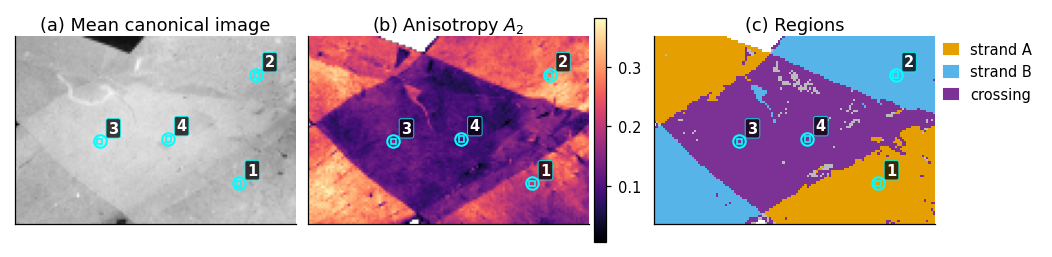

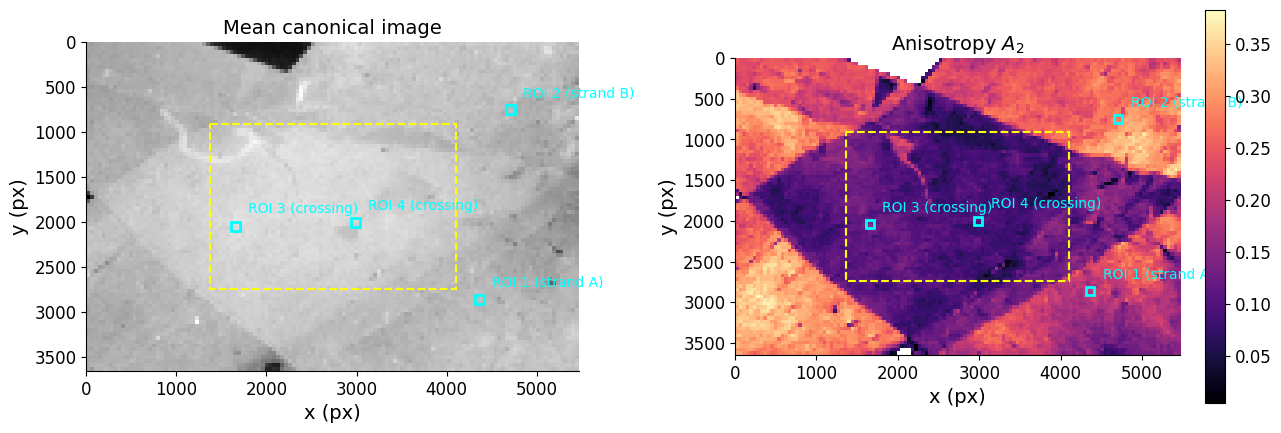

[cell run time: 24 s]


In [6]:
# ⏱ 1–3 min (reads the N_MAX canonical frames once)
def second_harmonic(profiles, n, harmonic=2):
    """
    Peak axis and anisotropy of line profiles (..., n).

    The angular Fourier coefficient c_k = sum_j z_j exp(i k phi_j) of a profile with two peaks 180 deg apart
    is dominant for k = 2. Its phase gives the axis of the peaks, theta = arg(c_2) / 2, and its magnitude
    relative to the mean intensity c_0 gives the anisotropy A_2 = |c_2| / c_0 (independent of brightness).
    """
    phi = np.deg2rad(physical_angles(n))
    c = np.tensordot(profiles, np.exp(1j * harmonic * phi), axes=([-1], [0]))
    c0 = np.sum(profiles, axis=-1)
    axis = (np.rad2deg(np.angle(c)) / harmonic) % (360.0 / harmonic)
    aniso = np.abs(c) / np.where(np.abs(c0) > 0, np.abs(c0), np.inf)
    return axis, aniso

# ----------------------------------------------------------------------------- ROI settings
TISSUE_PERCENTILE = 1     # pixels darker than this percentile of the mean image are excluded
ROI_SIZE = 100            # ROI side length in full-resolution pixels
ROIS = None               # None = automatic: ROI 1 strand A, ROI 2 strand B, ROI 3 + 4 crossing
ROI_NAMES = None          # labels for manually defined ROIS (list of str)
EXCLUDE_ROIS = []         # (x0, y0, w, h) regions to avoid, e.g. the ROIs of the original Hadamard article

# ----------------------------------------------------------------------------- maps of the binned section
first = read_frame(frame_files(STACK_DIRS[("can", N_MAX)], N_MAX)[0])
IMG_H, IMG_W = first.shape
if PREVIEW_BIN is None:
    PREVIEW_BIN = max(1, int(np.ceil(max(IMG_H, IMG_W) / 128)))
print(f"Frame size {IMG_H} x {IMG_W} px, binning {PREVIEW_BIN} x {PREVIEW_BIN}")

can_stack_preview = load_binned_stack(STACK_DIRS[("can", N_MAX)], N_MAX, PREVIEW_BIN)
mean_img = can_stack_preview.mean(axis=0)
axis_map, aniso_map = second_harmonic(np.moveaxis(can_stack_preview, 0, -1), N_MAX)
TISSUE_MASK = mean_img > np.percentile(mean_img, TISSUE_PERCENTILE)

# ----------------------------------------------------------------------------- regions and ROIs
# k-means on the second-harmonic phasors A2*exp(2i*theta) separates strand A, strand B and the crossing
CLASS_MAP, CLASS_NAMES, CLASS_PHASOR = classify_regions(axis_map, aniso_map, TISSUE_MASK, seed=SEED)
print("Class centres (mean over pixels of each class):")
for k, name in enumerate(CLASS_NAMES[:3]):
    c = CLASS_PHASOR[name]
    print(f"  {name:9s}: A2 = {abs(c):.3f}, peak axis = {(np.angle(c, deg=True) / 2) % 180:6.1f} deg, "
          f"pixels = {np.sum(CLASS_MAP == k)}")

if ROIS is None:
    ROIS = auto_rois(CLASS_MAP, (IMG_H, IMG_W), PREVIEW_BIN, roi_size=ROI_SIZE, exclude_rois=EXCLUDE_ROIS)
    ROI_NAMES = ["ROI 1 (strand A)", "ROI 2 (strand B)", "ROI 3 (crossing)", "ROI 4 (crossing)"]
if ROI_NAMES is None:
    ROI_NAMES = [f"ROI {r + 1}" for r in range(len(ROIS))]
if CALIB_ROI is None:
    CALIB_ROI = (IMG_W // 4, IMG_H // 4, IMG_W // 2, IMG_H // 2)

def roi_label(r):
    return ROI_NAMES[r] if r < len(ROI_NAMES) else f"ROI {r + 1}"

def with_roi_labels(df):
    """Copy of a results table with ROI names instead of the internal 0-based ROI index."""
    df = df.copy()
    if "ROI" in df:
        df["ROI"] = df["ROI"].map(roi_label)
    return df

for r, roi in enumerate(ROIS):
    print(f"{roi_label(r):18s} (x0, y0, w, h) = {roi}")
save_table(pd.DataFrame([{"ROI": roi_label(r), "x0": x0, "y0": y0, "w": w, "h": h}
                         for r, (x0, y0, w, h) in enumerate(ROIS)]), "table01_rois", kind="article")

sh.plot_overview(mean_img, aniso_map, TISSUE_MASK, CLASS_MAP, CLASS_NAMES, ROIS, (IMG_H, IMG_W), CALIB_ROI, roi_label)

### Anisotropy and the choice of ROIs

For every pixel the line profile $z_j = z(\varphi_j)$ is sampled at the $N$ physical illumination angles $\varphi_j$. Its angular Fourier coefficients are

$$ c_k = \sum_{j=0}^{N-1} z_j\, e^{\,ik\varphi_j}, \qquad c_0 = \sum_j z_j . $$

A strand of parallel in-plane fibres scatters light into two directions 180° apart, so its profile is dominated by the second harmonic ($k = 2$). The peak axis and anisotropy are defined as

$$ \text{peak axis: } \theta = \tfrac12 \arg c_2 \in [0^\circ, 180^\circ), \qquad \text{anisotropy: } A_2 = \frac{|c_2|}{c_0} \in [0, 1]. $$

$A_2$ is normalised by the total profile intensity $c_0$ and is unchanged by uniform intensity scaling. Where two strands overlap, the profile contains the peak pairs of both strands. Their second-harmonic contributions can partly cancel, reducing $A_2$ and yielding an intermediate peak axis.

The four ROIs represent the two types of line profiles that occur in the sample:

* **ROI 1, ROI 2 (single strands):** two dominant peaks 180° apart.
* **ROI 3, ROI 4 (crossing):** the peak pairs of both strands, i.e. four peaks.

[Sections 2](#scrollTo=0c4e2bc8) and [3](#scrollTo=03d3a406) compare their sparsity and the number of measurements needed for reconstruction. The second-harmonic axis describes the predominant scattering direction; it does not resolve the individual strands in a crossing region.

             ROI  peak axis theta (deg)    A2
ROI 1 (strand A)                   62.0 0.197
ROI 2 (strand B)                  124.0 0.279
ROI 3 (crossing)                   99.8 0.138
ROI 4 (crossing)                  103.2 0.095


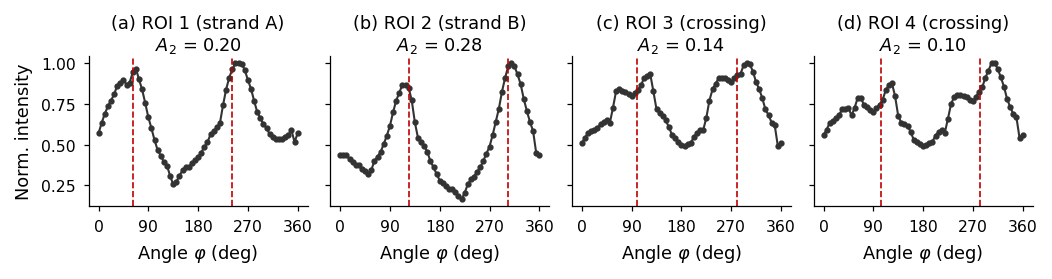

[cell run time: 7 s]


In [7]:
# ⏱ ~1 min (reads the ROIs from the N_MAX canonical frames)
n = N_MAX
roi_can = load_roi_profiles(STACK_DIRS[("can", n)], n, ROIS)
th2, A2 = second_harmonic(roi_can, n, harmonic=2)

ROI_TABLE = pd.DataFrame({"ROI": [roi_label(r) for r in range(len(ROIS))],
                          "peak axis theta (deg)": th2.round(1), "A2": A2.round(3)})
print(ROI_TABLE.to_string(index=False))
save_table(ROI_TABLE, "table02_roi_properties", kind="article")
sh.plot_roi_profiles(roi_can, th2, A2, n, roi_label)

**Discussion.**\
The clustering of the second-harmonic phasors separates the section into the two single strands and their overlap without a manually chosen angular threshold. The two strands have clearly different peak axes, and the crossing region has a lower $A_2$ with a peak axis between those of the strands, as expected for overlapping fibre populations. The canonical line profiles confirm the classification: The single-strand ROIs show one pair of peaks 180° apart (dashed lines: peak axis $\theta$ and $\theta + 180°$), the crossing ROIs show the peak pairs of both strands. Placing the ROIs inside each region reduces contamination from region boundaries.

#### Diagnostic: crossing ROIs (not part of the manuscript)

The next cell checks that the crossing ROIs are consistent with a superposition of the two strands: peak positions, an additive model of the second harmonic, and a non-negative fit of each crossing profile with the two strand profiles plus an offset. The results are saved under `results/diagnostics`.

Crossing angle between the strands: 62.0 deg
Additive model, equal strands: A2 = 0.117, axis = 102.1 deg
ROI 3 (crossing): measured A2 = 0.138, axis = 99.8 deg
ROI 4 (crossing): measured A2 = 0.095, axis = 103.2 deg

ROI 1 (strand A)   peaks at [ 68. 248. 349.] deg
ROI 2 (strand B)   peaks at [112. 309.] deg
ROI 3 (crossing)   peaks at [124. 298.] deg
ROI 4 (crossing)   peaks at [ 62. 124. 304.] deg

ROI 3 (crossing)
  fit A + B : NCC = 0.842, RMSE = 0.083, coefficients = [0.431 0.558 0.169]
  fit A only: NCC = 0.308, RMSE = 0.147, coefficients = [0.227 0.587]
  fit B only: NCC = 0.636, RMSE = 0.119, coefficients = [0.427 0.514]

ROI 4 (crossing)
  fit A + B : NCC = 0.928, RMSE = 0.048, coefficients = [0.368 0.523 0.209]
  fit A only: NCC = 0.288, RMSE = 0.123, coefficients = [0.177 0.602]
  fit B only: NCC = 0.736, RMSE = 0.087, coefficients = [0.412 0.504]


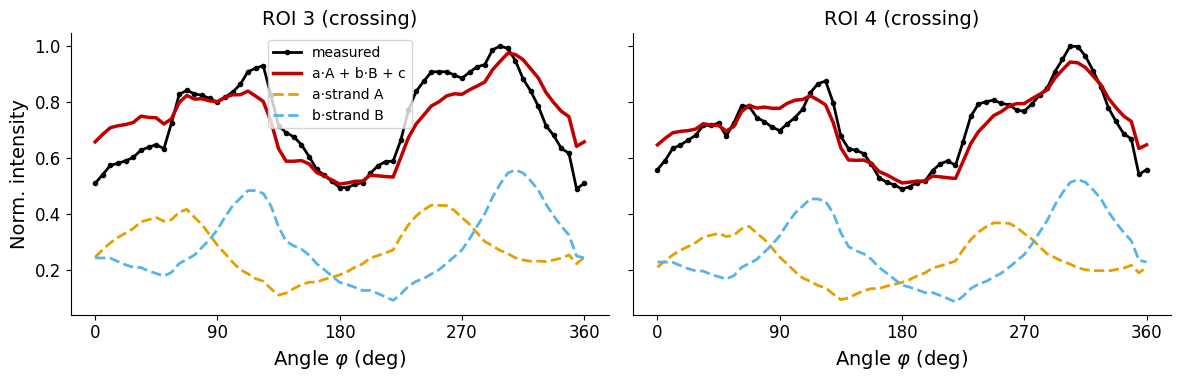

In [8]:
# ⏱ < 5 s
# Diagnostic (not part of the manuscript): consistency of the crossing ROIs with an additive two-strand model
from scipy.signal import find_peaks
from scipy.optimize import nnls

n = N_MAX

pA = A2[0] * np.exp(2j * np.deg2rad(th2[0]))
pB = A2[1] * np.exp(2j * np.deg2rad(th2[1]))
delta = axial_difference(th2[0], th2[1])
p_eq = 0.5 * (pA + pB)
print(f"Crossing angle between the strands: {delta:.1f} deg")
print(f"Additive model, equal strands: A2 = {np.abs(p_eq):.3f}, axis = {(np.angle(p_eq, deg=True) / 2) % 180:.1f} deg")
for r in (2, 3):
    print(f"{roi_label(r)}: measured A2 = {A2[r]:.3f}, axis = {th2[r]:.1f} deg")
print()

P = roi_can / roi_can.max(axis=1, keepdims=True)
ang = physical_angles(n)
order = np.argsort(ang)
ang_s = ang[order]

def peak_angles(z, prominence=0.05):
    # circular peak search: tile the sorted profile three times and keep peaks of the middle copy
    zs = z[order]
    idx, _ = find_peaks(np.tile(zs, 3), prominence=prominence)
    idx = idx[(idx >= n) & (idx < 2 * n)] - n
    return np.sort(ang_s[idx])

for r in range(len(ROIS)):
    print(f"{roi_label(r):18s} peaks at {np.round(peak_angles(P[r]), 0)} deg")

def fit_mixture(z, components):
    X = np.column_stack(components + [np.ones(n)])
    coef, _ = nnls(X, z)
    fit = X @ coef
    return coef, fit, ncc(fit, z), rmse(fit, z)

zA, zB = P[0], P[1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, r in zip(axes, (2, 3)):
    z = P[r]
    rows = []
    for name, comps in [("A + B", [zA, zB]), ("A only", [zA]), ("B only", [zB])]:
        coef, fit, c, e = fit_mixture(z, comps)
        rows.append((name, c, e, coef))
        if name == "A + B":
            fit_ab, coef_ab = fit, coef
    print(f"\n{roi_label(r)}")
    for name, c, e, coef in rows:
        print(f"  fit {name:6s}: NCC = {c:.3f}, RMSE = {e:.3f}, coefficients = {np.round(coef, 3)}")
    ax.plot(*prepare_profile_for_plot(z, n), "o-", ms=3, color="black", label="measured")
    ax.plot(*prepare_profile_for_plot(fit_ab, n), "-", lw=2.5, color="#C00000", label="a·A + b·B + c")
    ax.plot(*prepare_profile_for_plot(coef_ab[0] * zA, n), "--", color="#E69F00", label="a·strand A")
    ax.plot(*prepare_profile_for_plot(coef_ab[1] * zB, n), "--", color="#56B4E9", label="b·strand B")
    ax.set_title(roi_label(r)); ax.set_xticks(range(0, 361, 90)); ax.set_xlabel("Angle $\\varphi$ (deg)")
axes[0].set_ylabel("Norm. intensity"); axes[0].legend(fontsize=10)
fig.tight_layout(); savefig(fig, "diag01_crossing_decomposition"); plt.show()

## 1. Full-basis sampling: canonical vs Hadamard SLI

**Purpose of this section.** With all $N$ patterns, both the canonical basis $I_N$ and the Hadamard basis are complete and invertible, so in a noise-free, ideal system they reconstruct the same line profile exactly. Differences between the experimental profiles can therefore arise from noise, calibration or exposure rather than the choice of complete basis. This section establishes the full-basis Hadamard profile $z_\mathrm{full}$ as the reference for all compressive reconstructions, and the canonical profile $z_\mathrm{can}$ as an independent measurement of the same quantity.

**Recovering Hadamard measurements from binary patterns.** An LED display cannot emit negative light, so the patterns are the binary matrix $H^+ = (H + 1)/2$. Since the first natural-ordered row is all ones, the signed measurements follow from a single binary acquisition (Eq. 2 of the manuscript),

$$ y_0 = \frac{m_0}{\sqrt N}, \qquad y_k = \frac{2 m_k - m_0}{\sqrt N}, \quad k = 1,\dots,N-1, $$

where $m_k$ is the recorded intensity for pattern $k$ and $y = \tfrac{1}{\sqrt N} H x$ uses the orthonormal Hadamard matrix. The raw profile is $x = \tfrac{1}{\sqrt N}H^\top y$.

**Correction of the Hadamard data.** Every binary frame also contains a contribution $b$ that does not depend on the pattern (camera offset, ambient or unmodulated light). As shown below, this offset ends up entirely in the first segment of the Hadamard reconstruction, $x_0 = z_0 + b$, while all other segments are unbiased. With `CALIBRATION_MODE = "offset"` (default) $b$ is estimated for every profile from segment 0 and its two angular neighbours and removed from all coefficients. The alternatives are an empirical gain for segment 0 (`"first_segment"`), gains estimated per segment from the canonical data (`"estimated"`) or no correction (`"none"`). A gain enters the CS forward model as $\Theta = \Phi G \Psi$; for `"offset"`, $G = I$. The diagnostic below compares the corrections.

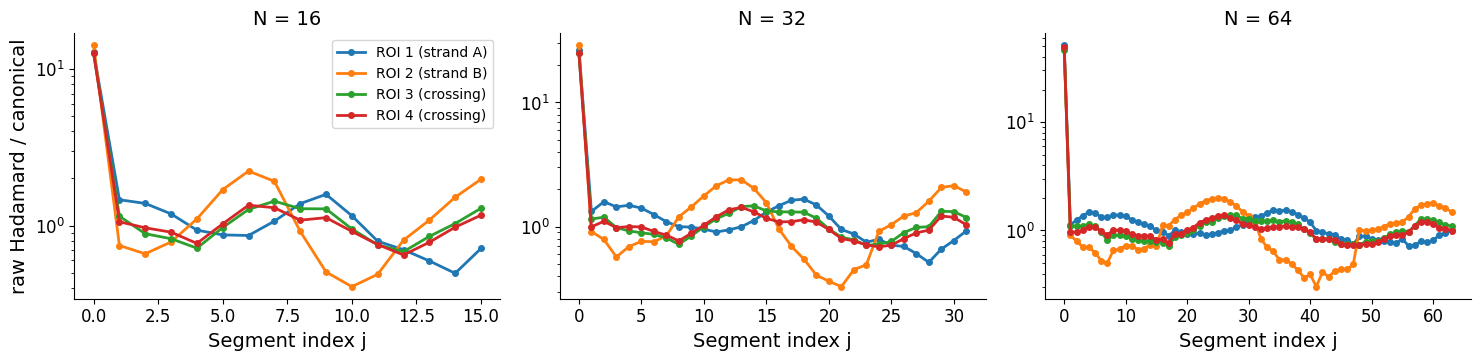

Error of segment 0 after correction (relative to the profile maximum; canonical as reference)
correction  first_segment    none  offset
N                                        
16                 -0.175   5.796   0.059
32                 -0.187  11.140  -0.014
64                 -0.181  21.721  -0.025

Mean NCC between corrected Hadamard and canonical profiles
correction  first_segment    none  offset
N                                        
16                 0.9758  0.2343  0.9886
32                 0.9816  0.1721  0.9915
64                 0.9821  0.1180  0.9869
[cell run time: 47 s]


In [9]:
# ⏱ 2–4 min (reads all remaining frames once; later sections use the cached data)
_H_CACHE, _PSI_CACHE = {}, {}

def hadamard_orthonormal(n):
    """Sylvester (natural-order) Hadamard matrix scaled by 1/sqrt(n), so that H @ H.T = I."""
    if n not in _H_CACHE:
        _H_CACHE[n] = hadamard(n).astype(float) / np.sqrt(n)
    return _H_CACHE[n]

def idct_basis(n):
    """Sparsifying basis Psi: the columns are orthonormal DCT atoms, so a profile is z = Psi @ s."""
    if n not in _PSI_CACHE:
        _PSI_CACHE[n] = idct(np.eye(n), axis=0, norm="ortho")
    return _PSI_CACHE[n]

def hplus_to_signed(m):
    """
    Binary frames m_k (patterns H+ = (H+1)/2) -> signed orthonormal Hadamard coefficients y_k, Eq. (2).

    Row 0 of H+ switches on all segments, every other row exactly half of them. Hence
    y_0 = m_0 / sqrt(N) and y_k = (2 m_k - m_0) / sqrt(N) for k >= 1: one binary acquisition replaces
    the two acquisitions H+ and H- that a +-1 pattern would otherwise need.
    """
    m = np.asarray(m, dtype=float)
    n = m.shape[-1]
    y = np.empty_like(m)
    y[..., 0] = m[..., 0]
    y[..., 1:] = 2.0 * m[..., 1:] - m[..., :1]
    return y / np.sqrt(n)

def raw_profile_from_coeffs(y):
    """Full-basis reconstruction x = H^T y (H is orthonormal and symmetric, so H^-1 = H^T = H)."""
    return y @ hadamard_orthonormal(y.shape[-1])

def remove_frame_offset(y):
    """
    Remove a pattern-independent frame offset b (camera offset, ambient light).

    With m_k = (H+ z)_k + b every signed coefficient gets the same extra term b/sqrt(N). Because only
    column 0 of H sums to N (all other columns sum to 0), the reconstruction becomes x_0 = z_0 + b while all
    other segments stay unbiased. b is estimated from segment 0 and its angular neighbours 1 and N-1, and
    b/sqrt(N) is subtracted from every coefficient, which changes only segment 0 of the reconstruction.
    """
    y = np.asarray(y, dtype=float)
    x = raw_profile_from_coeffs(y)
    b = x[..., 0] - 0.5 * (x[..., 1] + x[..., -1])
    return y - b[..., None] / np.sqrt(y.shape[-1]), b

def signed_coeffs(m, mode=None):
    """Binary frames -> signed coefficients, offset-corrected for CALIBRATION_MODE = "offset"."""
    mode = CALIBRATION_MODE if mode is None else mode
    y = hplus_to_signed(m)
    if mode == "offset":
        y, _ = remove_frame_offset(y)
    return y

def calibration_gains(n, mode=None):
    """Diagonal of G in the forward model x = G z (only used by the gain-based corrections)."""
    mode = CALIBRATION_MODE if mode is None else mode
    if mode in ("none", "offset"):
        return np.ones(n)
    if mode == "first_segment":
        g = np.ones(n); g[0] = n
        return g
    if mode == "estimated":                       # ratio of Hadamard and canonical profiles in CALIB_ROI
        can = load_roi_profiles(STACK_DIRS[("can", n)], n, [CALIB_ROI])[0]
        had = raw_profile_from_coeffs(hplus_to_signed(load_roi_profiles(STACK_DIRS[("had", n)], n, [CALIB_ROI])[0]))
        r = had / np.where(can != 0, can, np.nan)
        return r / np.nanmedian(r)
    raise ValueError("CALIBRATION_MODE must be 'offset', 'first_segment', 'estimated' or 'none'.")

# --- read every stack once: binned stack (Sections 6, 7) and ROI profiles (Sections 1-5)
CAN_RAW, HAD_FRAMES = {}, {}
for n in NS:
    _, CAN_RAW[n] = load_stack_and_rois(STACK_DIRS[("can", n)], n, PREVIEW_BIN, ROIS)
    _, HAD_FRAMES[n] = load_stack_and_rois(STACK_DIRS[("had", n)], n, PREVIEW_BIN, ROIS)
GAINS = {n: calibration_gains(n) for n in NS}

# --- diagnostic: per-segment ratio of raw Hadamard and canonical profiles
sh.plot_calibration_ratio({n: raw_profile_from_coeffs(hplus_to_signed(HAD_FRAMES[n])) for n in NS}, CAN_RAW, NS, roi_label)

# --- diagnostic: error that remains in segment 0 after each correction (canonical profile as reference)
rows = []
for n in NS:
    for mode in ["none", "first_segment", "offset"]:
        g = calibration_gains(n, mode)
        for r in range(len(ROIS)):
            z = raw_profile_from_coeffs(signed_coeffs(HAD_FRAMES[n][r], mode)) / g
            z = z / np.max(z[1:])
            can_m, _, _ = match_affine(CAN_RAW[n][r], z)            # canonical matched on segments 1..N-1
            rows.append({"N": n, "correction": mode, "ROI": r, "segment-0 error": z[0] - can_m[0],
                         "NCC vs canonical": ncc(z, CAN_RAW[n][r])})
CALIB_DF = pd.DataFrame(rows)
save_table(with_roi_labels(CALIB_DF), "diag02_calibration_comparison")
print("Error of segment 0 after correction (relative to the profile maximum; canonical as reference)")
print(CALIB_DF.pivot_table(index="N", columns="correction", values="segment-0 error").round(3).to_string())
print("\nMean NCC between corrected Hadamard and canonical profiles")
print(CALIB_DF.pivot_table(index="N", columns="correction", values="NCC vs canonical").round(4).to_string())

#### What the calibration diagnostic shows

For every ROI and every segment $j$, the figure shows the ratio

$$ R_j = \frac{x_j^\text{had}}{z_j^\text{can}} \Big/ \operatorname{median}_j\!\left(\frac{x_j^\text{had}}{z_j^\text{can}}\right), $$

where $x^\text{had}$ is the raw profile reconstructed from the binary Hadamard frames and $z^\text{can}$ is the canonical profile of the same ROI. Dividing by the median removes the different exposure times of the two acquisitions. For perfectly matching profiles, the curves would be flat at $R_j = 1$.

Two features are visible:

* **Segment 0 is strongly over-estimated** in all ROIs, and the excess grows with $N$ (roughly a factor of 15, 30 and 60 for $N = 16, 32, 64$).
* **All other segments** scatter around $R_j = 1$. These deviations come from noise and from small differences between the two independent acquisitions; they are not systematic.

#### Why only the first segment is affected

The binary patterns are $H^+ = \tfrac12(H + \mathbf{1}\mathbf{1}^\top)$, where $H$ is the $\pm1$ Hadamard matrix in natural order. The first row of $H^+$ is all ones; every other row switches on exactly $N/2$ segments. Every recorded frame also contains a contribution $b$ that does not depend on the pattern, for example the camera offset, ambient light or light that is not modulated by the display:

$$ m_k = (H^+ z)_k + b . $$

With the single-acquisition conversion (Eq. 2), the signed coefficients become

$$ m_0 = (Hz)_0 + b, \qquad 2m_k - m_0 = (Hz)_k + b \quad (k \ge 1), $$

so **every** coefficient carries the same offset: $\tilde y = \tfrac{1}{\sqrt N}\,(Hz + b\,\mathbf{1})$. Inverting with $H^\top H = N I$ gives

$$ x = \tfrac{1}{\sqrt N} H^\top \tilde y = z + \frac{b}{N}\, H^\top \mathbf{1} . $$

In natural order the first column of $H$ contains only $+1$, and every other column is orthogonal to it, so its entries sum to zero:

$$ (H^\top \mathbf{1})_j = \sum_k H_{kj} = N\,\delta_{j0} \quad\Rightarrow\quad x_j = z_j + b\,\delta_{j0} . $$

**The complete offset of all $N$ frames is collected in the first segment, and all other segments remain unbiased.** This is the price of measuring only $H^+$ instead of the differential pair $H^+$ and $H^- = \tfrac12(\mathbf{1}\mathbf{1}^\top - H)$. In $m^+_k - m^-_k = (Hz)_k$ the offset cancels exactly, but twice as many frames are needed.

#### Why the effect grows with $N$, and why it is even stronger in 2D SPI

The ratio for the first segment is

$$ R_0 = 1 + \frac{b}{z_0}, \qquad z_0 \approx \frac{1}{N}\sum_j z_j = \frac{S}{N} \quad\Rightarrow\quad R_0 - 1 \approx N\,\frac{b}{S}. $$

Each binary frame switches on half of the segments and therefore collects about $S/2$, while the offset $b$ per frame stays the same. The signal of a single segment, however, decreases as $S/N$. So the relative error in the first segment grows **linearly with $N$**, as observed for $N = 16, 32, 64$.

In 2D single-pixel imaging the same mechanism applies with $N = n \times n$ pixels, e.g. $N = 1024$ for a $32\times32$ image. The offset of all frames then ends up in a single pixel (the first pixel of the image in natural order). Relative to the signal of one pixel it is much larger than in SLI, and it appears as an isolated bright pixel or as an apparent DC artefact.

#### Consequence for the reconstruction

Since only $x_0$ is biased, the correction concerns the first segment only. The physically consistent correction is the subtraction of $b$, taken from a dark frame, from a known camera offset, or, as done here (`CALIBRATION_MODE = "offset"`), estimated from segment 0 and its two angular neighbours. Subtracting $b/\sqrt N$ from all signed coefficients changes only segment 0 of the reconstruction. The table below the diagnostic compares this correction with the empirical gain $G_{00}$: the error that remains in segment 0 after each correction is reported relative to the canonical profile. The estimate from the neighbours assumes that the profile is smooth across segment 0; it is slightly biased if a scattering peak lies exactly at the angle of segment 0. In a compressed acquisition $b$ is a property of the setup and is determined once, e.g. from a dark frame.

The cell below builds the data used in the rest of the notebook. All profiles are normalised to a maximum of one so that RMSE values are comparable between ROIs and $N$. The Hadamard coefficients $y$ are scaled with the same factor as the full Hadamard reconstruction, so the forward model stays linear. The figure shows: (a) raw canonical and binary Hadamard frames (separate axes, because the two acquisitions have different exposure times), (b) signed Hadamard coefficients, (c) the reconstructed profiles. The canonical profile is matched in scale and offset to the Hadamard profile, because its own constant offset raises its baseline (see the discussion below).

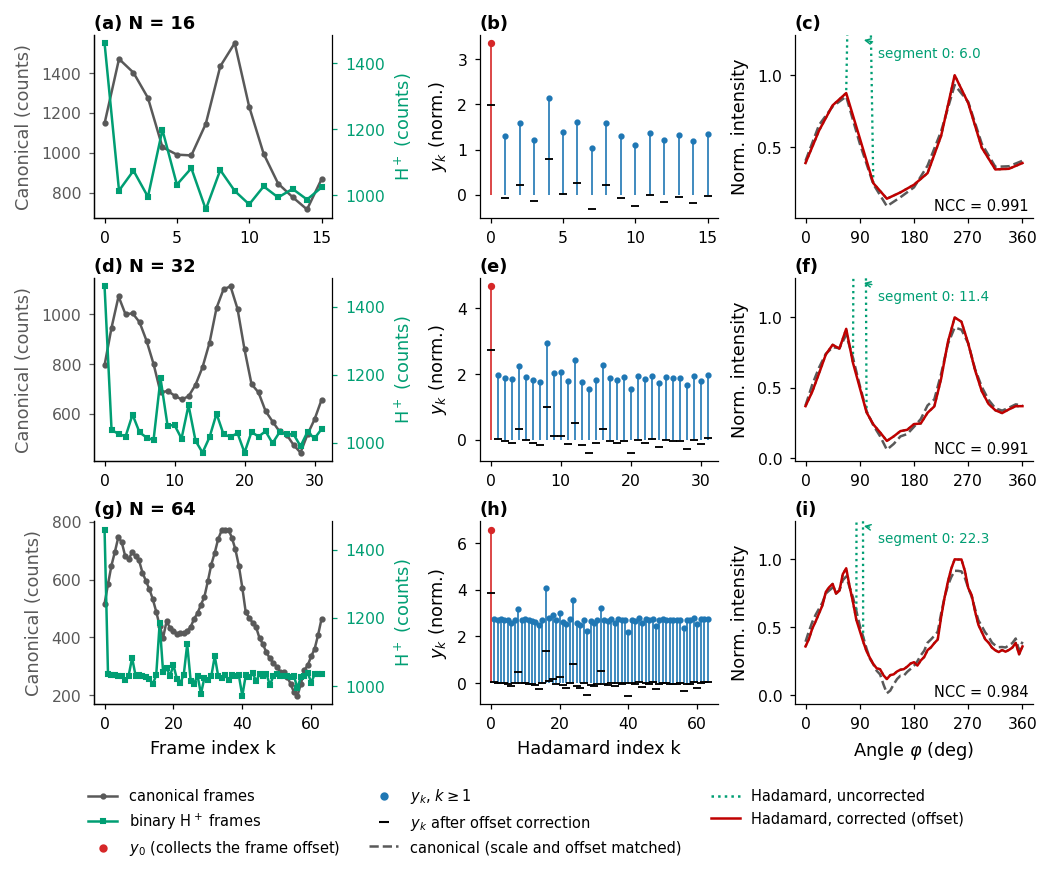

Agreement between full Hadamard and canonical profiles
             ROI  N    NCC  RMSE (max-normalised)  RMSE (matched)  canonical offset / max
ROI 1 (strand A) 16 0.9915                 0.2423          0.0332                  0.4025
ROI 2 (strand B) 16 0.9881                 0.2657          0.0432                  0.3600
ROI 3 (crossing) 16 0.9924                 0.2204          0.0278                  0.4523
ROI 4 (crossing) 16 0.9824                 0.2107          0.0366                  0.4671
ROI 1 (strand A) 32 0.9911                 0.2241          0.0339                  0.3559
ROI 2 (strand B) 32 0.9872                 0.2539          0.0458                  0.3330
ROI 3 (crossing) 32 0.9940                 0.2147          0.0242                  0.4148
ROI 4 (crossing) 32 0.9936                 0.2216          0.0205                  0.4181
ROI 1 (strand A) 64 0.9837                 0.1720          0.0463                  0.2428
ROI 2 (strand B) 64 0.9800                 0.

In [10]:
# ⏱ < 10 s
DATA = {}   # (roi, n) -> profiles and coefficients used in Sections 1-5
for n in NS:
    g = GAINS[n]
    for r in range(len(ROIS)):
        y_raw = hplus_to_signed(HAD_FRAMES[n][r])
        y = signed_coeffs(HAD_FRAMES[n][r])
        x_raw = raw_profile_from_coeffs(y_raw)                 # uncorrected Hadamard profile
        z_full = raw_profile_from_coeffs(y) / g                # corrected Hadamard profile = reference
        scale = np.max(z_full)                                 # y and z are scaled together (linear model)
        z_can = CAN_RAW[n][r] / CAN_RAW[n][r].max()
        z_can_matched, a_can, c_can = match_affine(z_can, z_full / scale)
        DATA[(r, n)] = dict(y=y / scale, y_raw=y_raw / scale, x_raw=x_raw / scale, z_full=z_full / scale,
                            z_can=z_can, z_can_matched=z_can_matched, can_offset=-c_can / a_can,
                            frames=HAD_FRAMES[n][r], can_frames=CAN_RAW[n][r], gains=g)

sh.plot_full_basis(DATA, NS, r_show=0, correction_label=CALIBRATION_MODE,
                  show_corrected_coeffs=(CALIBRATION_MODE == "offset"))

rows = []
for n in NS:
    for r in range(len(ROIS)):
        d = DATA[(r, n)]
        rows.append({"ROI": r, "N": n, "NCC": ncc(d["z_full"], d["z_can"]),
                     "RMSE (max-normalised)": rmse(d["z_full"], d["z_can"]),
                     "RMSE (matched)": rmse(d["z_full"], d["z_can_matched"]),
                     "canonical offset / max": d["can_offset"]})
FULL_DF = with_roi_labels(pd.DataFrame(rows).round(4))
print("Agreement between full Hadamard and canonical profiles")
print(FULL_DF.to_string(index=False))
save_table(FULL_DF, "table03_full_basis_agreement", kind="article");

**Discussion.**\
The correction table above confirms the offset model of the calibration diagnostic: without correction, segment 0 is too bright by several times the profile maximum, and the error grows with $N$. The empirical gain $G_{00} = N$ over-corrects segment 0 (residual error of about $-0.18$), whereas the offset correction leaves a residual of only a few per cent and gives the highest agreement with the canonical profiles.

With the full basis and the offset correction, canonical and Hadamard measurements give the same line profiles (NCC between 0.98 and 0.99 for all ROIs and all $N$). Two systematic differences remain visible, and both are explained by constant offsets of the frames rather than by the basis:

* **Uncorrected Hadamard profile:** the offset of all binary frames collects in segment 0 (the isolated peak at the angle of segment 0). After the correction, segment 0 follows its neighbours.
* **Canonical profile:** its own constant offset (25–47 % of the maximum, column "canonical offset / max") is spread over all segments and raises the baseline after normalisation to the maximum. This is why the RMSE of max-normalised profiles (about 0.2) is much larger than the RMSE after matching scale and offset (0.02–0.06), while the NCC, which is insensitive to offsets, is unaffected.

The remaining differences after matching come from noise and from the fact that the two acquisitions are independent measurements. The binary Hadamard frames carry only a few counts of signal per segment on top of the offset, so they are noisier than the canonical frames. The compressive reconstructions therefore use the full Hadamard profile of the **same acquisition** as their reference. This avoids including differences between independent acquisitions in the reconstruction error.

## 2. The two conditions of compressive sensing for SLI profiles

Compressive sensing recovers $z$ from $M < N$ measurements by solving

$$ \min_s \|s\|_1 \quad \text{subject to} \quad y = \Theta s, \qquad \Theta = \Phi G \Psi, \qquad z = \Psi s. $$

Reliable recovery from fewer measurements depends on **two main conditions**:

> **(i) Sparsity.** The signal has only $K \ll N$ significant coefficients in the sparsifying basis $\Psi$. For suitable incoherent measurement designs, the required number of measurements often scales as $M \sim K\log(N/K)$ (up to problem-dependent constants).
>
> **(ii) Incoherence.** The measurement vectors must not be concentrated on a few atoms of $\Psi$. It is quantified by the mutual coherence $\mu(\Phi,\Psi) = \sqrt N \max_{i,j} |\langle \phi_i, \psi_j\rangle| \in [1, \sqrt N]$. Small $\mu$ means measurements are distributed across the DCT coefficients, favouring recovery from fewer measurements.

Both conditions are tested below on the measured SLI profiles, with $\Psi$ fixed to the orthonormal DCT.

 N              ROI  K (95% AC energy)  M = K log(N/K) (95%)  K (99% AC energy)  M = K log(N/K) (99%)  CR predicted (99%)
16 ROI 1 (strand A)                  8                     8                 11                    11               0.688
16 ROI 2 (strand B)                  7                     7                  8                     8               0.500
16 ROI 3 (crossing)                  4                     6                  8                     8               0.500
16 ROI 4 (crossing)                  8                     8                 11                    11               0.688
32 ROI 1 (strand A)                  8                    12                 13                    13               0.406
32 ROI 2 (strand B)                  8                    12                 15                    15               0.469
32 ROI 3 (crossing)                  6                    11                 14                    14               0.438
32 ROI 4 (crossing)     

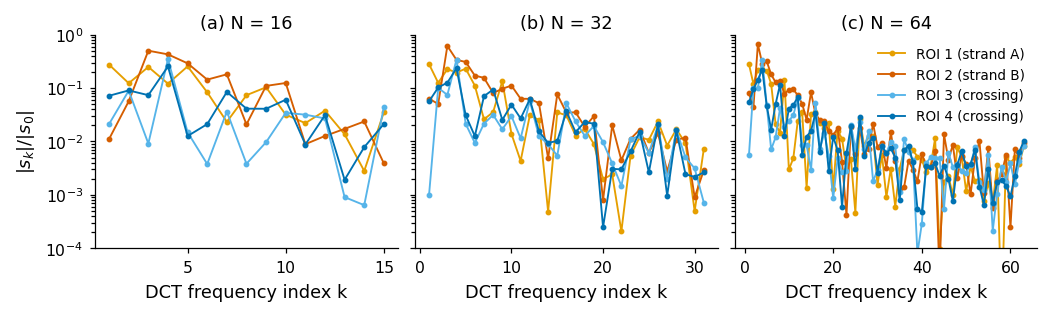

[cell run time: 4 s]


In [11]:
# ⏱ < 5 s
# Sparsity of the measured profiles in the DCT basis Psi: s = Psi^T z (orthonormal DCT of the profile).
# The DC coefficient s_0 (mean intensity) carries most of the energy of every profile and would make even flat
# profiles look sparse. K therefore counts the coefficients needed for a given fraction of the energy of the
# *modulation* (all coefficients except s_0), plus s_0 itself.
ENERGY_LEVELS = [0.95, 0.99]
rows, SPECTRA = [], {}
for n in NS:
    for r in range(len(ROIS)):
        s = dct(DATA[(r, n)]["z_full"], norm="ortho")
        SPECTRA[(r, n)] = s
        ac = np.sort(np.abs(s[1:]))[::-1]                      # modulation coefficients, largest first
        energy = np.cumsum(ac**2) / np.sum(ac**2)
        row = {"N": n, "ROI": r}
        for e in ENERGY_LEVELS:
            K = int(np.searchsorted(energy, e) + 1) + 1        # + DC coefficient
            row[f"K ({int(e*100)}% AC energy)"] = K
            # CS scaling law M ~ K log(N/K); at least K measurements are always needed
            row[f"M = K log(N/K) ({int(e*100)}%)"] = min(n, max(K, int(np.ceil(K * np.log(n / K)))))
        rows.append(row)

SPARSITY = pd.DataFrame(rows)
SPARSITY["CR predicted (99%)"] = (SPARSITY["M = K log(N/K) (99%)"] / SPARSITY["N"]).round(3)
print(with_roi_labels(SPARSITY).to_string(index=False))
save_table(with_roi_labels(SPARSITY), "table04_sparsity", kind="article")
sh.plot_dct_spectra(SPECTRA, NS, roi_label)

**Incoherence.**\
The next cell compares the coherence with the DCT of the canonical basis, the Hadamard basis and a random binary basis. Note that the Hadamard/DCT pair is *maximally coherent* ($\mu = \sqrt N$) because the all-ones Hadamard row is identical to the DC atom of the DCT. Removing the DC row does not help: further rows coincide exactly with DCT atoms (e.g. the atom with frequency index $N/2$), and low-sequency Hadamard rows are concentrated on low DCT frequencies. Hadamard SLI therefore does not satisfy the incoherence condition in the strict sense. This is why the **ordering** of the rows matters so much: since all orderings contain the same rows, they share the same $\mu$ for the full matrix, but they differ in which DCT frequencies are covered by the first $M$ rows. The lower row of the ordering figure in [Section 3](#scrollTo=03d3a406) shows $|\Phi\Psi|$ for the three orderings.

In [12]:
# ⏱ < 1 s
def mutual_coherence(Phi, Psi):
    """mu = sqrt(N) max |<phi_i, psi_j>| for normalised rows phi_i; 1 (incoherent) <= mu <= sqrt(N)."""
    Phi = Phi / np.linalg.norm(Phi, axis=1, keepdims=True)
    return np.sqrt(Psi.shape[0]) * np.max(np.abs(Phi @ Psi))

rows = []
for n in NS:
    Psi = idct_basis(n)
    Hn = hadamard_orthonormal(n)
    B = rng.choice([-1.0, 1.0], size=(n, n))          # random +-1 patterns
    rows.append({"N": n, "sqrt(N) (max)": np.sqrt(n),
                 "mu(canonical, DCT)": mutual_coherence(np.eye(n), Psi),
                 "mu(Hadamard, DCT)": mutual_coherence(Hn, Psi),
                 "mu(Hadamard without DC, DCT)": mutual_coherence(Hn[1:], Psi),
                 "mu(random ±1, DCT)": mutual_coherence(B, Psi)})
COHERENCE = pd.DataFrame(rows).round(3)
print(COHERENCE.to_string(index=False))
save_table(COHERENCE, "table05_mutual_coherence", kind="article");

 N  sqrt(N) (max)  mu(canonical, DCT)  mu(Hadamard, DCT)  mu(Hadamard without DC, DCT)  mu(random ±1, DCT)
16          4.000               1.407              4.000                         4.000               3.089
32          5.657               1.413              5.657                         5.657               3.192
64          8.000               1.414              8.000                         8.000               3.528


**Discussion.**\
The DCT spectra of all profiles decay quickly: apart from the DC coefficient, a few low angular frequencies carry most of the modulation. The number of significant coefficients hardly grows with $N$ (for 95 % of the modulation energy $K \approx 4$–11 across the examined ROIs and $N$): it is determined by the angular structure of the profile (two peaks of finite width for a single strand, the peak pairs of both strands for the crossing), not by the number of segments. As a heuristic, $M \sim K\log(N/K)$ grows more slowly than $N$, so the expected compression ratio decreases as $N$ increases. This scaling is not a recovery guarantee for the coherent Hadamard–DCT pair. [Section 3.3](#scrollTo=b3ead444) compares this prediction with the measured plateau of the reconstructions.

The coherence table shows that the Hadamard basis is maximally coherent with the DCT ($\mu = \sqrt N$), whereas canonical sampling is almost perfectly incoherent ($\mu \approx \sqrt 2$) and random $\pm1$ patterns lie in between. Hadamard SLI therefore does not satisfy the incoherence condition in the strict sense, and the success of CS depends on whether the first $M$ measured rows cover the DCT frequencies in which the profile is sparse. This is the reason why the ordering of the Hadamard rows is decisive ([Section 3](#scrollTo=03d3a406)).

## 3. Influence of the Hadamard ordering

**Fixed conditions of this comparison** (identical for all orderings): sparsifying basis $\Psi$ = orthonormal DCT, solver = basis pursuit from SPGL1 (`spg_bp`), calibration $G$ from [Section 1](#scrollTo=b243d8fd), reference = full Hadamard profile $z_\mathrm{full}$ of the same ROI. Only the order of the measurement vectors changes.

**Orderings.**
* *Natural Hadamard*: Kronecker (Sylvester) order.
* *Hadamard–Walsh*: sorted by sequency (number of sign changes). In 1D this is a low-pass sampling of the angular profile.
* *Cake-cutting*: originally defined for 2D patterns by the number of connected regions. For 1D angular patterns, the notebook uses a spectral analogue: rows are sorted by their spectrally weighted mean frequency. (`CAKE_CUTTING_MODE = "tutorial_2d"` applies the 2D definition to $\sqrt N\times\sqrt N$ patterns; this only exists for $N = 16, 64$ and has no physical meaning on a ring of LEDs.)

**Retrospective compression.** All $N$ binary patterns were acquired. Selecting the first $M$ patterns reproduces the coefficients of a prospective compressed acquisition, provided the all-on frame $m_0$ is included; the code checks that it is first in each ordering. The offset correction in this notebook is estimated from the full acquisition, however. A prospective measurement would require an independently determined offset.

All orderings are valid permutations with the all-on pattern first.


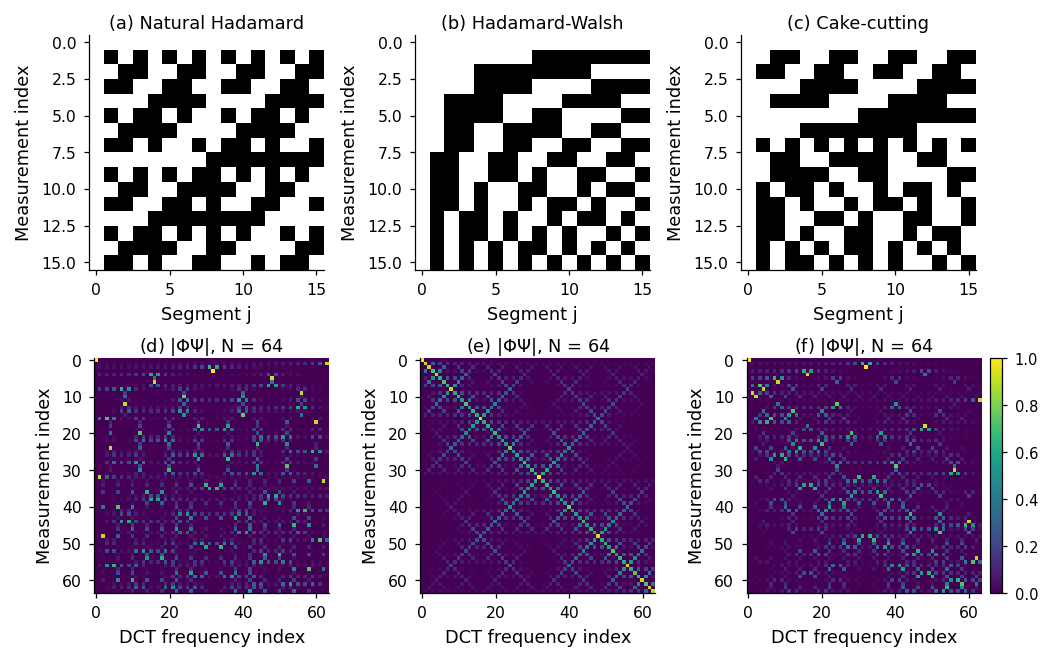

[cell run time: 7 s]


In [13]:
# ⏱ ~ 5 s
CAKE_CUTTING_MODE = "one_dimensional"   # or "tutorial_2d"

def walsh_order(n):
    """
    Sequency (Walsh) ordering of the natural Hadamard rows.

    The sequency index of natural row k follows from the bits of k: reverse the bit order and convert the
    result from Gray code to binary. Sorting by sequency (number of sign changes along the ring of segments)
    puts the lowest angular frequencies first.
    """
    n_bits = int(np.log2(n) + 1)
    bin_had = np.fliplr(np.array([[int(b) for b in bin(k)[2:].zfill(n_bits)] for k in range(n)]))  # bit reversal
    bin_seq = np.zeros_like(bin_had)
    for k in range(n_bits - 1, 0, -1):                                   # Gray code -> binary
        bin_seq[:, k] = np.logical_xor(bin_had[:, k], bin_had[:, k - 1])
    return (bin_seq @ (2 ** np.arange(n_bits - 1, -1, -1))).astype(int)

def cake_cutting_order_1d(n):
    """1D analogue of cake-cutting: rows sorted by their spectrally weighted mean frequency."""
    Hn = hadamard(n).astype(float)
    w = np.abs(np.fft.fftfreq(n))
    score = np.array([np.sum(np.abs(np.fft.fft(Hn[i])) * w) for i in range(n)])
    return np.argsort(score, kind="mergesort")

def cake_cutting_order_2d(n):
    """Original 2D definition applied to sqrt(N) x sqrt(N) patterns (only for square N, no meaning on a ring)."""
    side = int(round(np.sqrt(n)))
    if side * side != n:
        raise ValueError(f"2D cake-cutting needs a square N, got {n}.")
    P = hadamard(n).astype(float).reshape(n, side, side)
    yy, xx = np.mgrid[0:side, 0:side]
    R = np.hypot(yy - (side - 1) / 2, xx - (side - 1) / 2)
    score = np.array([np.sum(np.abs(np.fft.fftshift(np.fft.fft2(P[i]))) * R) for i in range(n)])
    return np.argsort(score, kind="mergesort")

ORDERINGS = {
    "Natural Hadamard": lambda n: np.arange(n),
    "Hadamard-Walsh": walsh_order,
    "Cake-cutting": cake_cutting_order_1d if CAKE_CUTTING_MODE == "one_dimensional" else cake_cutting_order_2d,
}

# checks: Walsh = sequency order; every ordering is a permutation that measures the all-on pattern first
for n in NS:
    Hn = hadamard(n)
    sign_changes = np.sum(Hn[:, 1:] != Hn[:, :-1], axis=1)
    assert np.array_equal(sign_changes[walsh_order(n)], np.arange(n)), "Walsh order is not sequency order"
    for name, f in ORDERINGS.items():
        o = f(n)
        assert sorted(o) == list(range(n)), f"{name} is not a permutation"
        assert o[0] == 0, f"{name}: the all-on (DC) pattern must be measured first"
print("All orderings are valid permutations with the all-on pattern first.")

# figure: patterns for N = 16 (top) and coupling |Phi Psi| of the ordered rows with the DCT atoms (bottom)
n_vis = 16 if 16 in NS else NS[0]
sh.plot_orderings({name: hadamard(n_vis)[f(n_vis)] for name, f in ORDERINGS.items()},
                  {name: np.abs(hadamard_orthonormal(N_MAX)[f(N_MAX)] @ idct_basis(N_MAX)) for name, f in ORDERINGS.items()},
                  n_vis, N_MAX)

### 3.1 Solvers and metrics

All solvers below estimate the DCT coefficients $s$ and reconstruct $z = \Psi s$. They are also used in [Sections 4](#scrollTo=61b987f3)–[7](#scrollTo=c7fbcbf5).

**Metrics.** Line profiles are 1D, so rather than the image metrics PSNR/SSIM, the comparison uses
* **RMSE** between normalised profiles,
* **NCC**, the normalised cross-correlation (shape similarity, insensitive to offsets and scaling),
* **direction error**: the axial difference (0° to 90°) between the dominant scattering axes obtained from the second angular harmonic of reconstructed and reference profiles. It is a simple, application-oriented proxy for the fibre-orientation analysis performed on SLI data (the full SLI evaluation is peak-based and also resolves crossing fibres). For maps and pixel statistics it is evaluated only where the reference profile is anisotropic ($A_2 \geq$ `DIR_MIN_A2`), because the axis of an almost isotropic profile is not defined.

In [14]:
# ⏱ < 1 s
import contextlib, io, logging
logging.getLogger("spgl1").setLevel(logging.ERROR)

ISTA_LAMBDA = 1e-3
ISTA_MAX_ITERS = 5000
BPDN_SIGMA_FRACTION = 0.02    # sigma = fraction * ||y||  (used when no noise estimate is given)
LASSO_TAU_FRACTION = 0.9      # tau   = fraction * ||s_BP||_1 (tau >= ||s_BP||_1 would not regularise)

def m_from_cr(cr, n):
    """Number of measurements M for a compression ratio CR = M/N (at least 1)."""
    return int(np.clip(np.ceil(cr * n), 1, n))

def soft_threshold(x, t):
    """Proximal operator of t*||x||_1: shrink every entry towards zero by t, set entries |x| <= t to zero."""
    return np.sign(x) * np.maximum(np.abs(x) - t, 0.0)

def ista(A, b, lam=ISTA_LAMBDA, max_iters=ISTA_MAX_ITERS, tol=1e-9):
    """
    Iterative soft thresholding for   min_s  1/2 ||A s - b||_2^2 + lam ||s||_1.

    Every iteration consists of
      1. a gradient step on the data term 1/2 ||A s - b||^2 (gradient A^T (A s - b)), and
      2. a soft-thresholding step, the proximal step of the l1 penalty, which sets small coefficients to zero.
    The step size 1/L with L = ||A||_2^2 (largest eigenvalue of A^T A) guarantees convergence.
    """
    s = np.zeros(A.shape[1])
    step = 1.0 / max(np.linalg.norm(A, 2) ** 2, 1e-12)
    for _ in range(max_iters):
        s_old = s
        grad = A.T @ (A @ s - b)                                 # 1. gradient of the data term
        s = soft_threshold(s - step * grad, lam * step)          # 2. proximal (shrinkage) step
        if np.linalg.norm(s - s_old) < tol:                      # stop when the update becomes negligible
            break
    return s

def solve(Theta, y, alg="bp", sigma=None):
    """Sparse coefficients s from y = Theta s with the chosen algorithm (SPGL1 messages are silenced)."""
    with contextlib.redirect_stdout(io.StringIO()):
        if alg == "pinv":           # minimum-norm least squares: min ||s||_2 s.t. Theta s = y (no sparsity prior)
            return np.linalg.pinv(Theta) @ y
        if alg == "ista":           # l1-regularised least squares (see ista above)
            return ista(Theta, y)
        if alg == "bp":             # basis pursuit: min ||s||_1 s.t. Theta s = y
            return spgl1.spg_bp(Theta, y, verbosity=0)[0]
        if alg == "bpdn":           # basis pursuit denoising: min ||s||_1 s.t. ||Theta s - y||_2 <= sigma
            sigma = BPDN_SIGMA_FRACTION * np.linalg.norm(y) if sigma is None else sigma
            return spgl1.spg_bpdn(Theta, y, sigma, verbosity=0)[0]
        if alg == "lasso":          # LASSO: min ||Theta s - y||_2 s.t. ||s||_1 <= tau, tau below ||s_BP||_1
            tau = LASSO_TAU_FRACTION * np.linalg.norm(spgl1.spg_bp(Theta, y, verbosity=0)[0], 1)
            return spgl1.spg_lasso(Theta, y, tau, verbosity=0)[0]
    raise ValueError(f"Unknown algorithm {alg}")

def cs_reconstruct(y_nat, order, M, gains, alg="bp", sigma=None):
    """
    Compressive reconstruction of one line profile from the first M measurements of an ordering.

    y_nat holds all signed coefficients in natural order. Keeping y_nat[order[:M]] is equivalent to acquiring
    only these M patterns. The forward model is y = Phi G z with Phi = the selected rows of the orthonormal
    Hadamard matrix and G the calibration gains; with the sparse representation z = Psi s this becomes
    y = Theta s with Theta = Phi G Psi. The solver returns s, and the profile is z = Psi s.
    """
    n = y_nat.size
    Phi = hadamard_orthonormal(n)[order[:M]]
    Psi = idct_basis(n)
    Theta = Phi @ (gains[:, None] * Psi)
    if M == n:                                     # complete basis: Theta is square and invertible
        s = np.linalg.solve(Theta, y_nat[order])
    else:
        s = solve(Theta, y_nat[order[:M]], alg, sigma)
    return Psi @ s

def direction_error(z_rec, z_ref, n):
    """Axial difference (deg) between the peak axes of a reconstructed and a reference profile."""
    return float(axial_difference(second_harmonic(np.asarray(z_rec), n)[0], second_harmonic(np.asarray(z_ref), n)[0]))

### 3.2 Ordering study on the measured data

468 reconstructions in 8.0 s


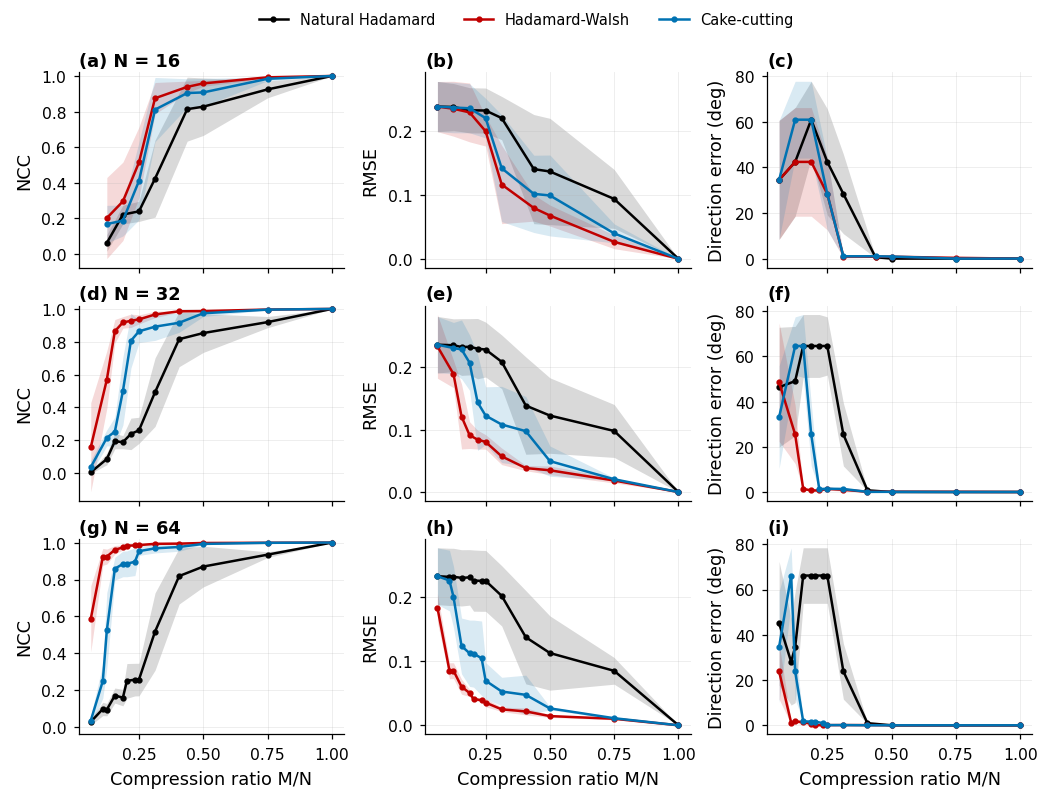

 N         ordering  requested_cr   ncc  rmse  direction_error
16     Cake-cutting         0.125 0.168 0.236           60.991
16     Cake-cutting         0.250 0.411 0.219           28.400
16     Cake-cutting         0.500 0.908 0.099            0.899
16   Hadamard-Walsh         0.125 0.202 0.234           42.457
16   Hadamard-Walsh         0.250 0.514 0.199           28.400
16   Hadamard-Walsh         0.500 0.958 0.067            0.831
16 Natural Hadamard         0.125 0.062 0.237           42.457
16 Natural Hadamard         0.250 0.240 0.231           42.457
16 Natural Hadamard         0.500 0.827 0.136            0.001
32     Cake-cutting         0.125 0.215 0.231           64.569
32     Cake-cutting         0.250 0.864 0.122            1.457
32     Cake-cutting         0.500 0.974 0.050            0.077
32   Hadamard-Walsh         0.125 0.569 0.189           25.431
32   Hadamard-Walsh         0.250 0.936 0.080            1.383
32   Hadamard-Walsh         0.500 0.987 0.035          

In [15]:
# ⏱ ~10–20 s
REF_KEY = "z_full"     # reference: "z_full" (same acquisition) or "z_can" (independent canonical measurement)
rows, RECON = [], {}
t0 = time.time()
for n in NS:
    for name, f in ORDERINGS.items():
        order = f(n)
        for cr in COMPRESSION_RATIOS:
            M = m_from_cr(cr, n)
            for r in range(len(ROIS)):
                d = DATA[(r, n)]
                z = cs_reconstruct(d["y"], order, M, d["gains"], alg="bp")
                RECON[(r, n, name, cr)] = z
                rows.append({"ROI": r, "N": n, "ordering": name, "requested_cr": cr, "cr": M / n, "M": M,
                             "rmse": rmse(z, d[REF_KEY]), "ncc": ncc(z, d[REF_KEY]),
                             "ncc_vs_canonical": ncc(z, d["z_can"]),
                             "direction_error": direction_error(z, d[REF_KEY], n)})
ORDER_DF = pd.DataFrame(rows)
save_table(with_roi_labels(ORDER_DF), "table06_ordering_metrics_long", kind="article")
print(f"{len(ORDER_DF)} reconstructions in {time.time() - t0:.1f} s")

METRICS = [("ncc", "NCC"), ("rmse", "RMSE"), ("direction_error", "Direction error (deg)")]
sh.plot_metric_vs_cr(ORDER_DF, "ordering", METRICS, NS, "fig06_ordering_metrics")

# compact summary table: mean NCC, RMSE and direction error per ordering at selected compression ratios
SUMMARY_CRS = [0.125, 0.25, 0.5]
summ = (ORDER_DF[ORDER_DF["requested_cr"].isin(SUMMARY_CRS)]
        .groupby(["N", "ordering", "requested_cr"])[["ncc", "rmse", "direction_error"]].mean().round(3).reset_index())
print(summ.to_string(index=False))
save_table(summ, "table07_ordering_summary", kind="article");

**Discussion.**\
With $\Psi$ and the solver fixed, the ordering alone changes the result drastically:

* **Hadamard–Walsh** gives the best reconstructions for the examined profiles at all $N$. Sorting by sequency means that the first $M$ measurements cover the lowest angular frequencies, which is exactly where the DCT spectra of the profiles are concentrated ([Section 2](#scrollTo=0c4e2bc8)). The ordering acts as a low-pass filter whose cut-off increases with $M$. At $\mathrm{CR} = 0.25$ the mean NCC is about 0.94 for $N = 32$ and 0.99 for $N = 64$; for $N = 64$ already $\mathrm{CR} = 0.125$ gives an NCC above 0.9.
* **Cake-cutting** (1D spectral analogue) is close to Walsh for $N = 32$ and 64, because it also prioritises low frequencies but mixes in some higher ones; it needs slightly larger CR.
* **Natural order** is clearly worse and does not reach an NCC of 0.9 even at $\mathrm{CR} = 0.5$. Its first rows sample a few isolated frequencies, so the profile is aliased and the peak positions, hence the directions, are wrong at low CR.

The required compression ratio decreases with $N$: $N = 16$ needs $\mathrm{CR} \approx 0.5$ for an NCC above 0.95, $N = 64$ only $\mathrm{CR} \approx 0.15$. This is the behaviour predicted by the sparsity analysis: the number of required measurements is set by the angular content of the profile, not by $N$. Once the NCC exceeds about 0.9, the direction error drops to one or two degrees. At very low $M$ the error scatters strongly, because a profile reconstructed from a handful of coefficients has no well-defined peak axis.

### 3.3 Plateau and best reconstructions

For each ROI and $N$, the notebook selects (only $\mathrm{CR} \le 0.5$ is considered, because larger ratios bring little practical gain):
* the **first plateau point**: the smallest CR whose NCC is within `PLATEAU_NCC_DELTA` of the maximum NCC (and above `PLATEAU_MIN_NCC` if reachable),
* the **best** reconstruction: highest NCC (ties broken by lower RMSE and lower CR).

The plateau CR is the practical answer to "how many patterns do I need?", and can be compared with the sparsity prediction of [Section 2](#scrollTo=0c4e2bc8).

             ROI  N     selection       ordering  M    cr   ncc  rmse  direction_error
ROI 1 (strand A) 16 First plateau Hadamard-Walsh  7 0.438 0.956 0.075            1.151
ROI 1 (strand A) 16          Best Hadamard-Walsh  7 0.438 0.956 0.075            1.151
ROI 1 (strand A) 32 First plateau Hadamard-Walsh  7 0.219 0.947 0.082            0.649
ROI 1 (strand A) 32          Best   Cake-cutting 16 0.500 0.995 0.026            0.154
ROI 1 (strand A) 64 First plateau Hadamard-Walsh 10 0.156 0.986 0.043            0.108
ROI 1 (strand A) 64          Best Hadamard-Walsh 32 0.500 0.999 0.014            0.002
ROI 2 (strand B) 16 First plateau Hadamard-Walsh  7 0.438 0.931 0.103            0.347
ROI 2 (strand B) 16          Best Hadamard-Walsh  8 0.500 0.964 0.075            0.543
ROI 2 (strand B) 32 First plateau Hadamard-Walsh  8 0.250 0.956 0.085            1.304
ROI 2 (strand B) 32          Best Hadamard-Walsh 16 0.500 0.995 0.030            0.032
ROI 2 (strand B) 64 First plateau Hadamard-

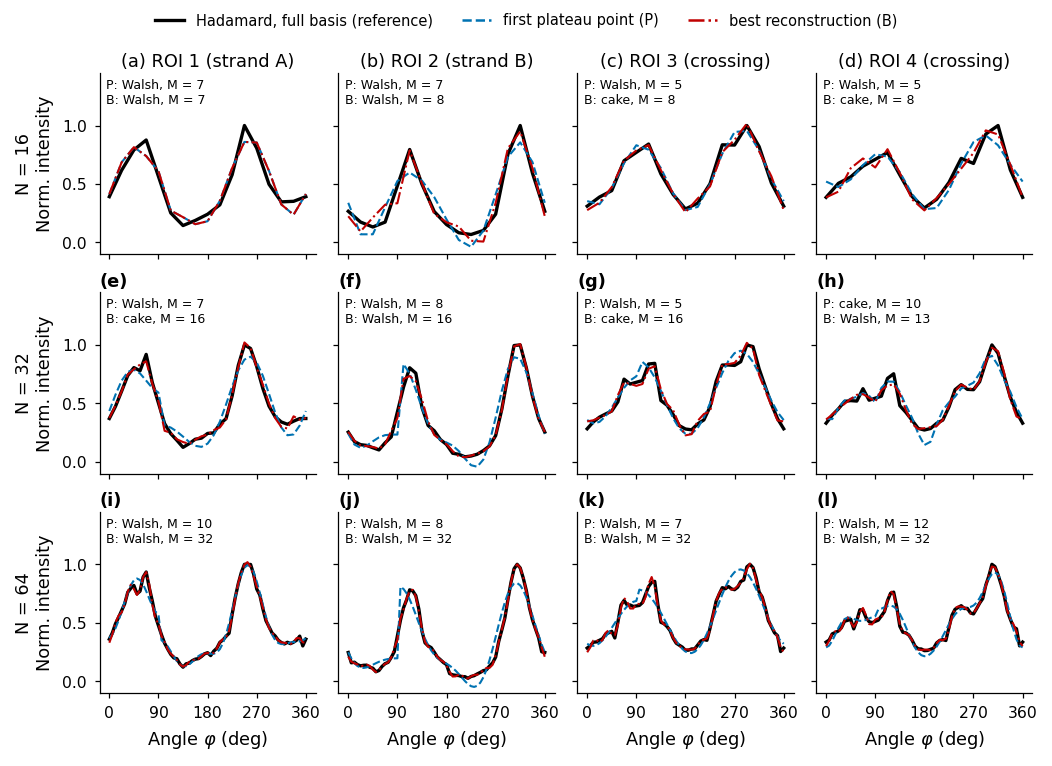

[cell run time: 5 s]


In [16]:
# ⏱ ~10 s
MAX_CR_FOR_SELECTION = 0.50
PLATEAU_NCC_DELTA = 0.05
PLATEAU_MIN_NCC = 0.90

def select_plateau_and_best(df):
    """Per ROI and N: first CR that reaches the NCC plateau, and the best reconstruction (CR <= 0.5)."""
    out = []
    for (r, n), g in df[df["cr"] <= MAX_CR_FOR_SELECTION + 1e-9].groupby(["ROI", "N"]):
        g = g[np.isfinite(g["ncc"])]
        best = g.sort_values(["ncc", "rmse", "cr"], ascending=[False, True, True]).iloc[0]
        thr = best["ncc"] - PLATEAU_NCC_DELTA
        cand = g[g["ncc"] >= max(thr, PLATEAU_MIN_NCC)]
        if cand.empty:
            cand = g[g["ncc"] >= thr]
        plateau = cand.sort_values(["cr", "ncc", "rmse"], ascending=[True, False, True]).iloc[0]
        for row, lab in [(plateau, "First plateau"), (best, "Best")]:
            row = row.copy(); row["selection"] = lab; out.append(row)
    return pd.DataFrame(out).reset_index(drop=True)

SELECTED = select_plateau_and_best(ORDER_DF)
SEL_COLS = ["ROI", "N", "selection", "ordering", "M", "cr", "ncc", "rmse", "direction_error"]
print(with_roi_labels(SELECTED[SEL_COLS]).round(3).to_string(index=False))
save_table(with_roi_labels(SELECTED[SEL_COLS]).round(4), "table08_plateau_best", kind="article")

# measured plateau vs. sparsity prediction of Section 2
plat = SELECTED[SELECTED["selection"] == "First plateau"][["ROI", "N", "ordering", "M"]].rename(
    columns={"M": "M plateau (measured)", "ordering": "plateau ordering"})
cmp_df = plat.merge(SPARSITY[["ROI", "N", "K (99% AC energy)", "M = K log(N/K) (99%)"]], on=["ROI", "N"])
cmp_df = with_roi_labels(cmp_df)
print("\nMeasured plateau vs. prediction M = K log(N/K)")
print(cmp_df.to_string(index=False))
save_table(cmp_df, "table09_plateau_vs_sparsity", kind="article")

sh.plot_plateau_best(DATA, SELECTED, RECON, NS, len(ROIS), roi_label)

**Discussion.**\
The first plateau point is reached with a similar *number* of measurements for all $N$ (5–12 measurements, column "M plateau"), so the plateau *compression ratio* decreases strongly with $N$: from about 0.3–0.45 for $N = 16$ to about 0.11–0.19 for $N = 64$. The measured plateau lies below the heuristic sparsity estimate $M \sim K \log(N/K)$ of [Section 2](#scrollTo=0c4e2bc8) (8–24 measurements for the 99 % criterion). These criteria differ: the plateau allows some loss in NCC, whereas the DCT criterion retains 99 % of the modulation energy. The estimate is not a strict bound for this coherent measurement basis.

Hadamard–Walsh provides the plateau point in almost all cases; cake-cutting occasionally reaches the best NCC at $\mathrm{CR} = 0.5$. In this sample, single-strand and crossing ROIs reach the plateau with comparable $M$: the crossing angle of about 60° does not create angular structure that is much finer than the peak width of a single strand. At the plateau, the reconstructions reproduce the main peak structure; the remaining differences are mostly in the peak amplitudes and in the noise of the reference.

### 3.4 Reconstructions as a function of the compression ratio

The SLI analogue of the image grid in the original tutorial: rows are orderings, columns are compression ratios, for one single-strand ROI and one crossing ROI at the same $N$ (grey: full Hadamard reference).

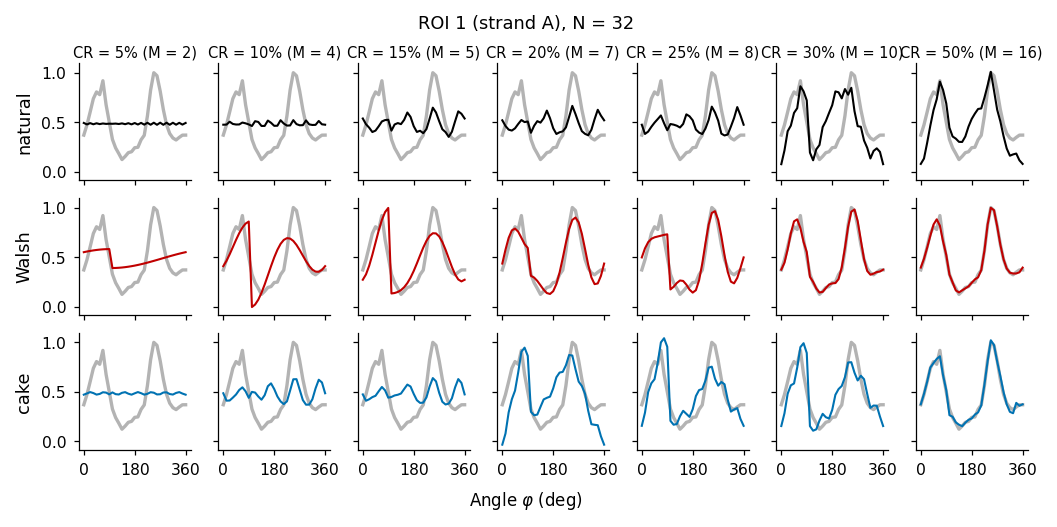

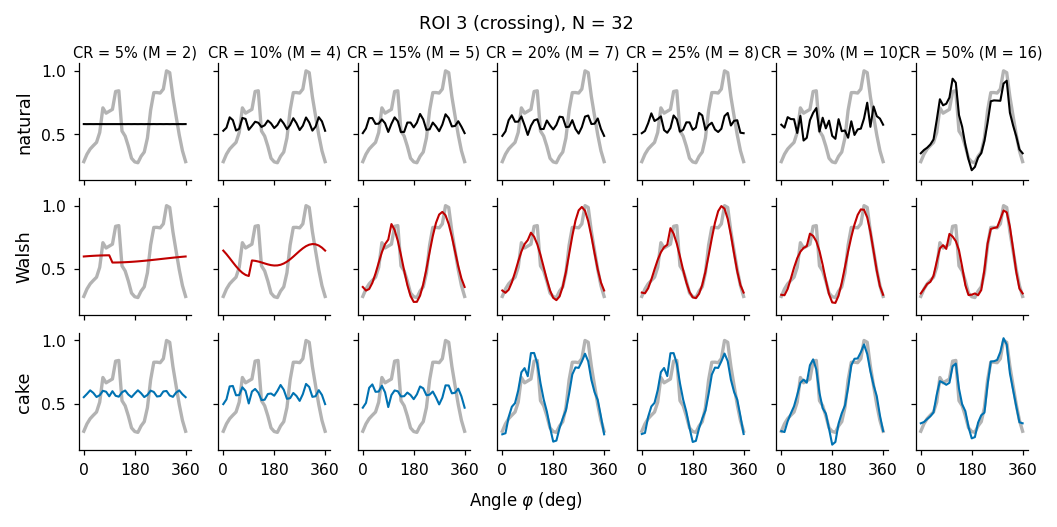

[cell run time: 12 s]


In [17]:
# ⏱ ~10 s
GRID_ROIS = [0, 2] if len(ROIS) > 2 else [0]           # ROI 1 (strand A) and ROI 3 (crossing)
n_show = 32 if 32 in NS else NS[-1]
crs_show = [c for c in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.50] if c in COMPRESSION_RATIOS]
for k, r_show in enumerate(GRID_ROIS):
    sh.plot_reconstruction_grid(DATA[(r_show, n_show)]["z_full"],
                                {(name, cr): RECON[(r_show, n_show, name, cr)] for name in ORDERINGS for cr in crs_show},
                                list(ORDERINGS), crs_show, n_show, f"{roi_label(r_show)}, N = {n_show}",
                                f"fig08{chr(97 + k)}_reconstruction_grid_roi{r_show + 1}", m_from_cr)

**Discussion.**\
The grids show *how* the orderings fail at low CR. The natural ordering produces aliased profiles with peaks at wrong positions, which explains its large direction errors. The Walsh ordering produces smooth, low-pass versions of the profile: the peak positions are correct early, while the peak widths and amplitudes converge with growing $M$. Cake-cutting lies in between and shows small ripples from the higher frequencies it samples early. For the crossing ROI the separation of the two peak pairs requires a few more measurements than the single peak pair of the strand, but at $\mathrm{CR} \approx 0.3$ the main peak structure is visible with the cake-cutting ordering.

## 4. Influence of the reconstruction algorithm

**Fixed conditions** for all algorithms: Hadamard–Walsh ordering, sparsifying basis $\Psi$ = orthonormal DCT, the same measured coefficients and calibration as in [Section 3](#scrollTo=03d3a406).

| Key | Algorithm | Problem solved |
|---|---|---|
| `pinv` | minimum-norm least squares (baseline without sparsity prior) | $\min\|s\|_2$ s.t. $\Theta s = y$ |
| `ista` | iterative soft thresholding (own implementation) | $\min \tfrac12\|\Theta s - y\|_2^2 + \lambda\|s\|_1$ |
| `bp` | SPGL1 basis pursuit | $\min\|s\|_1$ s.t. $\Theta s = y$ |
| `bpdn` | SPGL1 basis pursuit denoising | $\min\|s\|_1$ s.t. $\|\Theta s - y\|_2 \le \sigma$ |
| `lasso` | SPGL1 LASSO | $\min\|\Theta s - y\|_2$ s.t. $\|s\|_1 \le \tau$ |

The regularisation parameters ($\lambda$, $\sigma$, $\tau$) are set in [Sec. 3.1](#scrollTo=49efa09f) relative to the data, so that they are meaningful for any normalisation. For LASSO, a loose $\ell_1$ constraint provides little regularisation. The notebook uses $\tau = 0.9\,\|s_\mathrm{BP}\|_1$, so its runtime also includes a BP solve. Runtimes are reported as well, because reconstruction time is the main argument for the learned reconstruction of [Section 6](#scrollTo=825cdb22).

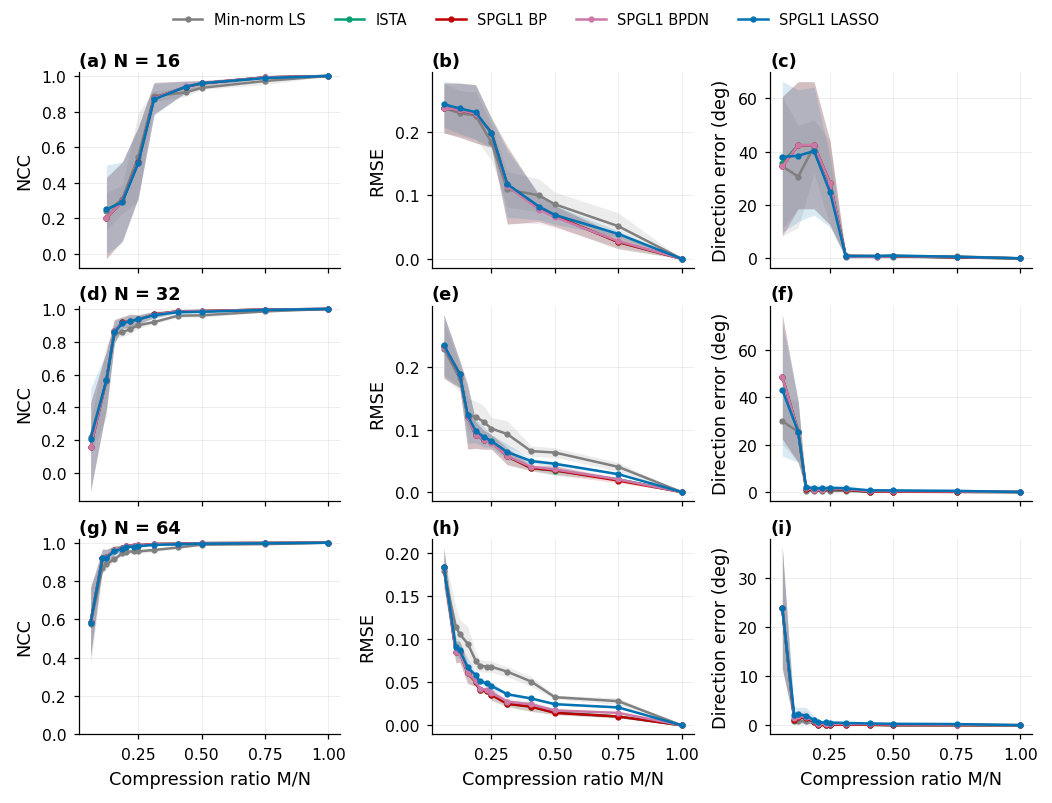

Median reconstruction time per profile (ms), CR < 1
N              16     32     64
algorithm                      
ISTA         4.28  13.39   9.27
Min-norm LS  0.15   0.26   0.31
SPGL1 BP     8.16  17.59  16.37
SPGL1 BPDN   3.72   6.78   5.57
SPGL1 LASSO  9.57  20.29  18.69
[cell run time: 15 s]


In [18]:
# ⏱ ~30 s
ALGORITHMS = {"pinv": "Min-norm LS", "ista": "ISTA", "bp": "SPGL1 BP", "bpdn": "SPGL1 BPDN", "lasso": "SPGL1 LASSO"}
rows = []
for n in NS:
    order = walsh_order(n)
    for cr in COMPRESSION_RATIOS:
        M = m_from_cr(cr, n)
        for key, label in ALGORITHMS.items():
            for r in range(len(ROIS)):
                d = DATA[(r, n)]
                t = time.perf_counter()
                z = cs_reconstruct(d["y"], order, M, d["gains"], alg=key)
                dt = time.perf_counter() - t
                rows.append({"ROI": r, "N": n, "algorithm": label, "cr": M / n, "M": M,
                             "rmse": rmse(z, d[REF_KEY]), "ncc": ncc(z, d[REF_KEY]),
                             "direction_error": direction_error(z, d[REF_KEY], n), "time_ms": 1e3 * dt})
ALG_DF = pd.DataFrame(rows)
save_table(with_roi_labels(ALG_DF), "table10_algorithm_metrics_long", kind="article")

sh.plot_metric_vs_cr(ALG_DF, "algorithm", METRICS, NS, "fig09_algorithm_metrics", colors=ALG_COLORS)

RUNTIME = (ALG_DF[ALG_DF["cr"] < 1].pivot_table(index="algorithm", columns="N", values="time_ms", aggfunc="median")
           .round(2))
print("Median reconstruction time per profile (ms), CR < 1")
print(RUNTIME.to_string())
save_table(RUNTIME.reset_index(), "table11_algorithm_runtime_ms", kind="article");

**Discussion.**\
 The algorithms fall into two groups:

* **Sparsity-promoting solvers with an exact or near-exact data constraint** (SPGL1 BP and BPDN) give the best reconstructions at all compression ratios and are almost indistinguishable, because the noise level assumed for BPDN is small.
* **Solvers that behave like least squares** (minimum-norm LS, and ISTA with the chosen $\lambda$) only reproduce the measured low-frequency content and are clearly worse in the range $\mathrm{CR} \approx 0.15$–0.5, where CS matters.

The behaviour of LASSO depends on $\tau$: with $\tau$ close to $\|s_\mathrm{BP}\|_1$ it approaches BP, smaller $\tau$ shrinks the coefficients and smooths the profile, which increases RMSE but can reduce noise. Differences between the solvers are largest for $N = 16$, where few measurements are available in absolute terms.

The runtimes are the practical limitation. SPGL1 BP needs about 6–12 ms per profile (BPDN 3–4 ms), minimum-norm least squares about 0.2 ms. For the $\sim 2\times10^7$ pixels of a full SLI image this means days of computing time on one CPU core for basis pursuit, although each pixel is only a tiny linear problem ([Section 7.1](#scrollTo=273feac5) gives the extrapolation). This motivates the learned linear reconstruction in [Section 6](#scrollTo=825cdb22).

## 5. Noise robustness (diagnostic)

*This section is a diagnostic simulation. Its results are saved under `results/diagnostics`.*

SLI, like most SPI applications, is often light-limited: thin sections scatter weakly, and short exposures are needed for large sections. This diagnostic compares measurement bases and reconstruction algorithms under a defined noise model. Because the true profile is unknown in an experiment, a **simulation based on measured data** is used: the canonical profile of a ROI (averaged over many pixels to reduce noise, with its constant offset removed as in [Section 1](#scrollTo=b243d8fd)) serves as ground truth $z$, and each frame is simulated as a camera pixel

$$ f_k = \mathrm{Poisson}\!\left(P\,(B z)_k\right) + \mathcal{N}(0, \sigma_r^2), $$

with $P$ the expected number of photo-electrons per segment and frame, $B$ the binary pattern matrix ($I$ for canonical, $H^+$ for Hadamard, random $\{0,1\}$ patterns), and camera read noise $\sigma_r$. Two regimes are compared:

* **shot-noise limited** ($\sigma_r = 0$): no multiplex advantage is expected in this model,
* **read-noise limited** ($\sigma_r > 0$): switching on several segments increases the signal per frame without increasing the read noise per frame, providing a multiplex advantage under the assumed exposure conditions.

`bpdn` receives the expected noise norm $\sigma$ of the used measurements (in an experiment it is estimated from repeated or dark frames). Every point is averaged over `NOISE_TRIALS` noise realisations.

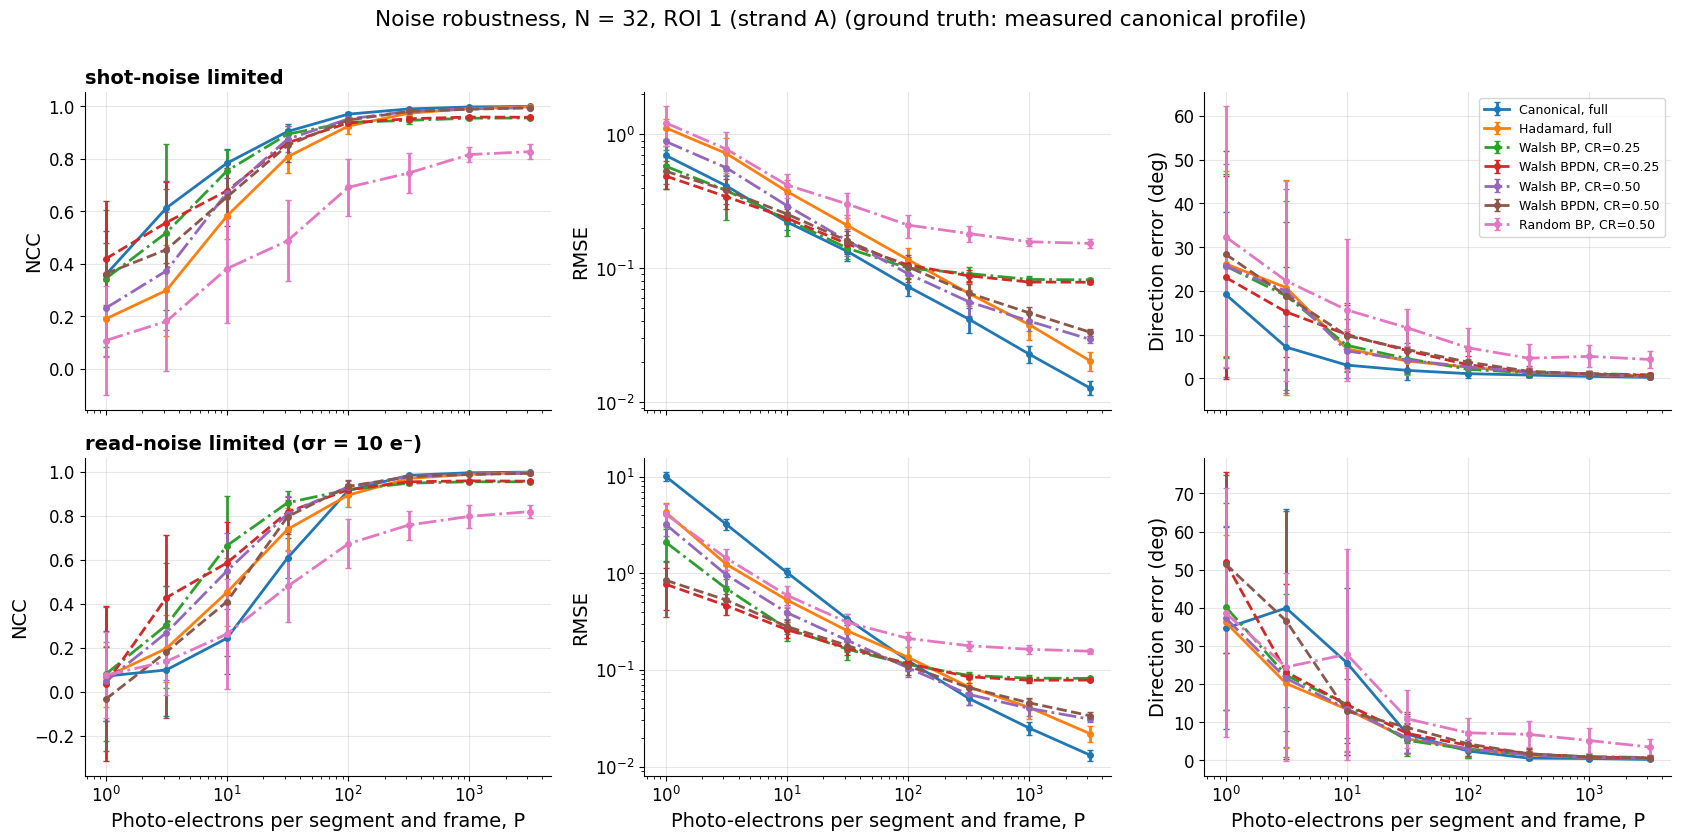

[cell run time: 47 s]


In [19]:
# ⏱ ~45 s
NOISE_N = 32 if 32 in NS else NS[0]
NOISE_ROI = 0
PHOTON_LEVELS = np.logspace(0, 3.5, 8)        # photo-electrons per segment and frame
READ_NOISE = {"shot-noise limited": 0.0, "read-noise limited (σr = 10 e⁻)": 10.0}
NOISE_TRIALS = 20
NOISE_CRS = [0.25, 0.5]

# ground truth: canonical profile with its constant offset removed (matched to the full Hadamard profile, Sec. 1)
z_true = np.clip(DATA[(NOISE_ROI, NOISE_N)]["z_can_matched"], 0, None)
z_true = z_true / z_true.max()
n = NOISE_N
Hp = (hadamard(n) + 1) / 2                               # binary Hadamard patterns H+
B_rand = rng.integers(0, 2, size=(n, n)).astype(float)   # random binary patterns (full rank)
B_rand[0] = 1.0
while np.linalg.matrix_rank(B_rand) < n:
    B_rand[1:] = rng.integers(0, 2, size=(n - 1, n))
Psi, H_on, w_order = idct_basis(n), hadamard_orthonormal(n), walsh_order(n)

def simulate(B, P, sr):
    """
    Camera signal for the binary patterns B (rows) and the ground truth z_true:
    photon (Poisson) noise of the expected signal P*(B z) plus Gaussian read noise sr per frame.
    Returns the frames in units of z and their standard deviation.
    """
    mean = P * (B @ z_true)
    return (rng.poisson(mean) + rng.normal(0, sr, mean.shape)) / P, np.sqrt(mean + sr**2) / P

def noise_methods(P, sr):
    """Reconstructions of one noise realisation with all compared bases and solvers."""
    out = {}
    f, _ = simulate(np.eye(n), P, sr)                    # canonical: one segment per frame, z = frames
    out["Canonical, full"] = f
    m, std_m = simulate(Hp, P, sr)                       # Hadamard: binary frames -> signed coefficients (Eq. 2)
    y = hplus_to_signed(m)
    # noise of y_k = (2 m_k - m_0)/sqrt(N): variances of the two frames add (4 var m_k + var m_0)
    std_y = np.sqrt(4 * std_m**2 + std_m[0] ** 2) / np.sqrt(n); std_y[0] = std_m[0] / np.sqrt(n)
    out["Hadamard, full"] = H_on.T @ y
    for cr in NOISE_CRS:                                 # compressive: first M Walsh coefficients
        M = m_from_cr(cr, n)
        idx = w_order[:M]
        Theta = H_on[idx] @ Psi
        out[f"Walsh BP, CR={cr:.2f}"] = Psi @ solve(Theta, y[idx], "bp")
        # BPDN with the expected noise norm of the used coefficients as sigma
        out[f"Walsh BPDN, CR={cr:.2f}"] = Psi @ solve(Theta, y[idx], "bpdn", sigma=np.linalg.norm(std_y[idx]))
    b, _ = simulate(B_rand, P, sr)                       # random binary patterns, first M rows
    M = m_from_cr(NOISE_CRS[-1], n)
    out[f"Random BP, CR={NOISE_CRS[-1]:.2f}"] = Psi @ solve(B_rand[:M] @ Psi, b[:M], "bp")
    return out

rows = []
for regime, sr in READ_NOISE.items():
    for P in PHOTON_LEVELS:
        for trial in range(NOISE_TRIALS):
            for method, z in noise_methods(P, sr).items():
                rows.append({"regime": regime, "photons": P, "trial": trial, "method": method,
                             "rmse": rmse(z, z_true), "ncc": ncc(z, z_true),
                             "direction_error": direction_error(z, z_true, n)})
NOISE_DF = pd.DataFrame(rows)
save_table(NOISE_DF, "diag03_noise_metrics")
sh.plot_noise_study(NOISE_DF, list(READ_NOISE), n,
                    f"Noise robustness, N = {n}, {roi_label(NOISE_ROI)} (ground truth: measured canonical profile)")

**Discussion.**\
The simulation separates the two noise regimes clearly:

* **Shot-noise limited:** canonical sampling is better than full Hadamard sampling at every light level. With the single-acquisition scheme each signed coefficient is $2m_k - m_0$, which combines the photon noise of two frames, and the multiplexed frames collect the photon noise of $N/2$ segments. There is no multiplex advantage.
* **Read-noise limited:** at low light ($P \lesssim 30$ photo-electrons per segment and frame) Hadamard sampling and the compressive reconstructions are better than canonical sampling, because each frame collects the light of many segments while the read noise per frame stays the same. At high light the canonical curve crosses over again.

Compressive reconstructions trade noise for truncation error. At low light they are often better than the full Hadamard inversion, because discarding the high-sequency measurements also discards their noise, and BPDN is the most robust solver there. At high light their error saturates at the truncation error of the chosen CR. Random binary patterns are the least favourable choice for these smooth profiles.

The simulation does not include the constant frame offset $b$ found in [Section 1](#scrollTo=b243d8fd). In the measured Hadamard data, the offset is large relative to the signal per segment. Any unmodulated optical background also adds photon noise, whereas a fixed electronic offset does not. The diagnostic therefore does not represent every noise source of the experimental acquisition.

## 6. Learned linear reconstruction

Deterministic solvers need an iterative optimisation per profile, which is slow for the $10^6$–$10^7$ pixels of an SLI image. A learned reconstruction moves the cost to a training phase. The CS problem is written as a regression,

$$ (W^\star, b^\star) = \arg\min_{W, b} \sum_i \big\| z_i - (W y_i + b) \big\|_2^2 + \lambda \|W\|_F^2, $$

i.e. a single fully connected (linear) layer that maps the $M$ measured coefficients to the $N$ angular samples.

**Two ways to obtain the same layer: closed form and Adam.** The quadratic loss makes the optimisation convex. The linear layer can be fitted in two ways:

* **Closed form (ridge regression).** With $X_a = [X,\mathbf{1}]$ (the training inputs with an added column for the bias) and target profiles $T$, the solution follows from $(X_a^\top X_a + \Lambda)W_a = X_a^\top T$. The diagonal matrix $\Lambda$ penalises the reconstruction weights, but not the bias; its strength is set relative to the input scale in the code. One linear solve gives the ridge-regression solution without iterative training.
* **Adam (iterative training).** The layer starts from random weights, and the weights are updated in small steps along the negative gradient of the loss, computed on random mini-batches of the training data. Adam scales every step with running estimates of the mean and variance of the gradient (parameters $\beta_1, \beta_2$), which adapts the update size to each weight. Training stops when the loss on the validation pixels no longer improves (early stopping), which also helps limit overfitting. The same gradient-based principle is used for many nonlinear neural networks.

For this linear model, the two approaches can give similar reconstructions, although ridge regularisation and early stopping are not identical. The closed-form fit provides a useful reference for assessing Adam training.

**Data.** Every binned pixel of the measured section provides one line profile. The pixels are split into three interleaved sets of $8\times8$-pixel blocks (training, validation, test), so that different sample regions are represented in every set without reusing any pixel. Inputs are the first $M$ **measured** Hadamard coefficients in the chosen ordering (offset-corrected as in [Section 1](#scrollTo=b243d8fd)), targets are the full Hadamard profiles of the same pixels. Two training sources are compared:

* **`hadamard`:** pairs of measured coefficients and full Hadamard profiles of the training pixels. This corresponds to one complete calibration acquisition, after which the instrument is operated in compressed mode. Input and target contain the real noise and calibration of the setup.
* **`canonical`:** measured canonical profiles of the training pixels; the coefficients are simulated with the forward model $y = \Phi G z$ plus Gaussian noise for augmentation.

All profiles are divided by the DC coefficient $y_0$, which is always measured, so the mapping does not depend on the brightness of the pixel.

**Model selection.** For every $N$, ordering and compression ratio (the same compression ratios as for SPGL1), the training source, the ridge parameter $\lambda$, the augmentation noise and the training method (closed form or Adam) are chosen by the mean NCC on the **validation** pixels, using their real measured coefficients as input. The selected model, called "learned (best)" below, is then evaluated once on the test pixels. All candidates are saved as a diagnostic table, so the selection can be inspected.

{'train': 3535, 'val': 3534, 'test': 3492} pixels
Selected training source and method (number of configurations):
method        Adam  closed form
N  source                      
16 canonical     0            3
   hadamard      8           25
32 canonical     0            2
   hadamard     10           24
64 hadamard      3           33

Validation NCC, Adam minus best closed form: median -0.0001, range -0.0819 ... +0.0011; Adam epochs: median 82


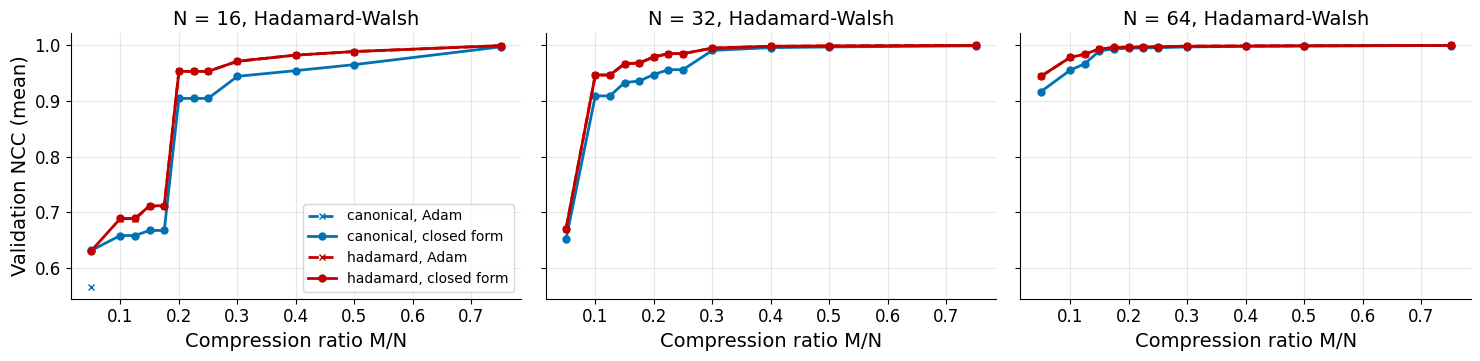

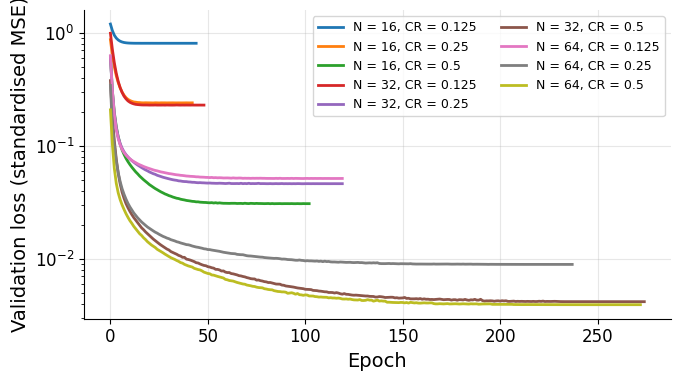

[cell run time: 2.7 min]


In [20]:
# ⏱ 2–5 min (selection of 108 configurations, Adam training of the selected ones)
# ----------------------------------------------------------------------------- settings
DL_NS = list(NS)
DL_CRS = [c for c in COMPRESSION_RATIOS if c < 1.0]      # same compression ratios as the SPGL1 studies
DL_ORDERINGS = list(ORDERINGS)
DL_SOURCES = ["hadamard", "canonical"]
DL_RIDGE_GRID = [1e-6, 1e-4, 1e-2, 1e0]                   # lambda relative to the mean diagonal of X^T X
DL_NOISE_GRID = [0.0, 0.01, 0.03]                         # augmentation noise (canonical source only)
DL_TRAIN_ADAM = HAS_TORCH
DL_LR = 1e-2                                              # Adam learning rate (halved on validation plateaus)
DL_MAX_EPOCHS = 300
DL_PATIENCE = 20                                          # early stopping on the validation loss
DL_BATCH = 256
DL_ADAM_BETAS = (0.9, 0.999)
DL_BLOCK = 8                                              # block size (binned pixels) of the data split

# ----------------------------------------------------------------------------- data: every binned pixel is a profile
# Interleaved 8x8 blocks are assigned to training / validation / test, so all tissue types are in every set.
Hb, Wb = TISSUE_MASK.shape
yy_b, xx_b = np.mgrid[0:Hb, 0:Wb]
blk = ((yy_b // DL_BLOCK) + (xx_b // DL_BLOCK)) % 3
SPLIT = {"train": TISSUE_MASK & (blk == 0), "val": TISSUE_MASK & (blk == 1), "test": TISSUE_MASK & (blk == 2)}
print({k: int(v.sum()) for k, v in SPLIT.items()}, "pixels")

DLDATA = {}
for n in DL_NS:
    can_b = load_binned_stack(STACK_DIRS[("can", n)], n, PREVIEW_BIN)      # cached in Section 1
    had_b = load_binned_stack(STACK_DIRS[("had", n)], n, PREVIEW_BIN)
    assert can_b.shape[1:] == TISSUE_MASK.shape == had_b.shape[1:], "stacks and tissue mask differ in size"
    Y = signed_coeffs(np.moveaxis(had_b, 0, -1))           # measured, offset-corrected coefficients (Hb, Wb, n)
    Z = raw_profile_from_coeffs(Y) / GAINS[n]              # full Hadamard profiles (targets / reference)
    C = np.moveaxis(can_b, 0, -1)                          # canonical profiles (alternative training source)
    valid = TISSUE_MASK & (Y[..., 0] > 0.05 * np.median(Y[..., 0][TISSUE_MASK]))   # DC term must not vanish
    DLDATA[n] = {"Y_map": Y, "Z_map": Z, "C_map": C, "valid": valid,
                 **{f"{k}_{s}": arr[SPLIT[s] & valid] for s in SPLIT for k, arr in (("Y", Y), ("Z", Z), ("C", C))}}

# ----------------------------------------------------------------------------- the linear layer
def fit_ridge(X, T, lam):
    """
    Closed-form training: solve the normal equations (Xa^T Xa + lambda I) W_a = Xa^T T.

    Xa = [X, 1] appends a column of ones, so the last row of W_a is the bias b. lambda is given relative to
    the mean diagonal of Xa^T Xa (independent of the scaling of X); the bias is not penalised.
    """
    Xa = np.hstack([X, np.ones((len(X), 1))])
    G_ = Xa.T @ Xa
    reg = lam * np.mean(np.diag(G_)) * np.eye(G_.shape[0]); reg[-1, -1] = 0.0
    Wa = np.linalg.solve(G_ + reg, Xa.T @ T)
    return Wa[:-1], Wa[-1]

def predict(model, y_meas):
    """Reconstruct profiles from measured coefficients (P, M): normalise by y_0, apply W and b, undo the scaling."""
    W, b = model
    dc = y_meas[:, :1]
    return ((y_meas / dc) @ W + b) * dc

def train_adam(X, T, Xv, Tv):
    """
    Iterative training of the same linear layer with Adam.

    Inputs and targets are standardised (zero mean, unit variance per feature) so that one learning rate
    suits all weights. Mini-batch gradient steps minimise the mean squared error; the learning rate is halved
    when the validation loss stagnates, and training stops (early stopping) when it has not improved for
    DL_PATIENCE epochs. The weights of the best epoch are converted back to the original units.
    """
    mx, sx = X.mean(0), X.std(0); sx[sx < 1e-12] = 1.0
    mt, st = T.mean(0), T.std(0); st[st < 1e-12] = 1.0
    f = lambda A, m, s: torch.tensor((A - m) / s, dtype=torch.float32)
    Xt, Tt, Xvt, Tvt = f(X, mx, sx), f(T, mt, st), f(Xv, mx, sx), f(Tv, mt, st)
    torch.manual_seed(SEED)
    layer = torch.nn.Linear(X.shape[1], T.shape[1])                    # random initial weights
    opt = torch.optim.Adam(layer.parameters(), lr=DL_LR, betas=DL_ADAM_BETAS)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5)
    loss_fn = torch.nn.MSELoss()
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(DL_MAX_EPOCHS):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), DL_BATCH):                          # one epoch of mini-batch updates
            idx = perm[i:i + DL_BATCH]
            opt.zero_grad()
            loss = loss_fn(layer(Xt[idx]), Tt[idx])
            loss.backward()                                            # gradient of the loss
            opt.step()                                                 # Adam update of W and b
        with torch.no_grad():
            vl = loss_fn(layer(Xvt), Tvt).item()                       # validation loss
        hist.append(vl); sched.step(vl)
        if vl < best - 1e-7:
            best, wait = vl, 0
            best_state = {k: v.clone() for k, v in layer.state_dict().items()}
        else:
            wait += 1
            if wait >= DL_PATIENCE:                                    # early stopping
                break
    layer.load_state_dict(best_state)
    Wt, bt = layer.weight.detach().numpy().T, layer.bias.detach().numpy()
    W = Wt / sx[:, None] * st[None, :]                                 # undo the standardisation
    b = (bt - (mx / sx) @ Wt) * st + mt
    return (W, b), hist

def training_pairs(n, source, idx, noise):
    """
    Training inputs (first M coefficients) and targets, both divided by the DC coefficient y_0.
    "hadamard":  measured coefficients and full Hadamard profiles of the training pixels.
    "canonical": canonical profiles; coefficients simulated with y = Phi G z plus Gaussian noise.
    """
    d = DLDATA[n]
    if source == "hadamard":
        Y, Z = d["Y_train"][:, idx], d["Z_train"]
    else:
        Z = d["C_train"] / d["C_train"].max(axis=1, keepdims=True)
        Y = Z @ (hadamard_orthonormal(n)[idx] * GAINS[n]).T
        if noise > 0:
            level = np.sqrt(np.mean(Y[:, 1:] ** 2)) if Y.shape[1] > 1 else np.mean(np.abs(Y))
            Y = Y + noise * level * rng.standard_normal(Y.shape)
    dc = Y[:, :1]
    return Y / dc, Z / dc

def evaluate(model, n, idx, split):
    """Mean NCC of the reconstructions of a data split, using its real measured coefficients as input."""
    d = DLDATA[n]
    Zp = predict(model, d[f"Y_{split}"][:, idx])
    return Zp, nanmean_quiet(ncc_rows(Zp, d[f"Z_{split}"]))

# ----------------------------------------------------------------------------- model selection and training
cand_rows, DL_BEST, ADAM_HIST = [], {}, {}
for n in DL_NS:
    for name in DL_ORDERINGS:
        order = ORDERINGS[name](n)
        for cr in DL_CRS:
            M = m_from_cr(cr, n)
            idx = order[:M]
            best = None
            # 1. closed form for every training source, augmentation noise and lambda
            for source in DL_SOURCES:
                for noise in (DL_NOISE_GRID if source == "canonical" else [0.0]):
                    X, T = training_pairs(n, source, idx, noise)
                    for lam in DL_RIDGE_GRID:
                        model = fit_ridge(X, T, lam)
                        _, v = evaluate(model, n, idx, "val")
                        row = {"N": n, "ordering": name, "cr": cr, "M": M, "source": source, "noise": noise,
                               "lambda": lam, "method": "closed form", "val_ncc": v}
                        cand_rows.append(row)
                        if best is None or v > best["val_ncc"]:
                            best = {**row, "model": model}
            # 2. Adam on the best source / noise; validation inputs are the measured coefficients
            if DL_TRAIN_ADAM:
                X, T = training_pairs(n, best["source"], idx, best["noise"])
                yv = DLDATA[n]["Y_val"][:, idx]
                model, hist = train_adam(X, T, yv / yv[:, :1], DLDATA[n]["Z_val"] / yv[:, :1])
                _, v = evaluate(model, n, idx, "val")
                ADAM_HIST[(n, name, cr)] = hist
                row = {"N": n, "ordering": name, "cr": cr, "M": M, "source": best["source"], "noise": best["noise"],
                       "lambda": 0.0, "method": "Adam", "val_ncc": v, "epochs": len(hist)}
                cand_rows.append(row)
                if v > best["val_ncc"]:
                    best = {**row, "model": model}
            DL_BEST[(n, name, cr)] = best                       # 3. selected model ("learned (best)")

CAND_DF = pd.DataFrame(cand_rows)
save_table(CAND_DF, "diag04_learned_model_candidates")
BEST_DF = pd.DataFrame([{k: v for k, v in b.items() if k != "model"} for b in DL_BEST.values()])
save_table(BEST_DF, "diag05_learned_model_selected")
print("Selected training source and method (number of configurations):")
print(BEST_DF.groupby(["N", "source", "method"]).size().unstack(fill_value=0).to_string())
if DL_TRAIN_ADAM:
    adam = CAND_DF[CAND_DF["method"] == "Adam"].set_index(["N", "ordering", "cr"])["val_ncc"]
    ridge = CAND_DF[(CAND_DF["method"] == "closed form")].groupby(["N", "ordering", "cr"])["val_ncc"].max()
    diff = (adam - ridge.loc[adam.index]).dropna()
    print(f"\nValidation NCC, Adam minus best closed form: median {diff.median():+.4f}, "
          f"range {diff.min():+.4f} ... {diff.max():+.4f}; Adam epochs: median "
          f"{int(CAND_DF.loc[CAND_DF['method'] == 'Adam', 'epochs'].median())}")

sh.plot_model_selection(CAND_DF, DL_NS, ADAM_HIST)

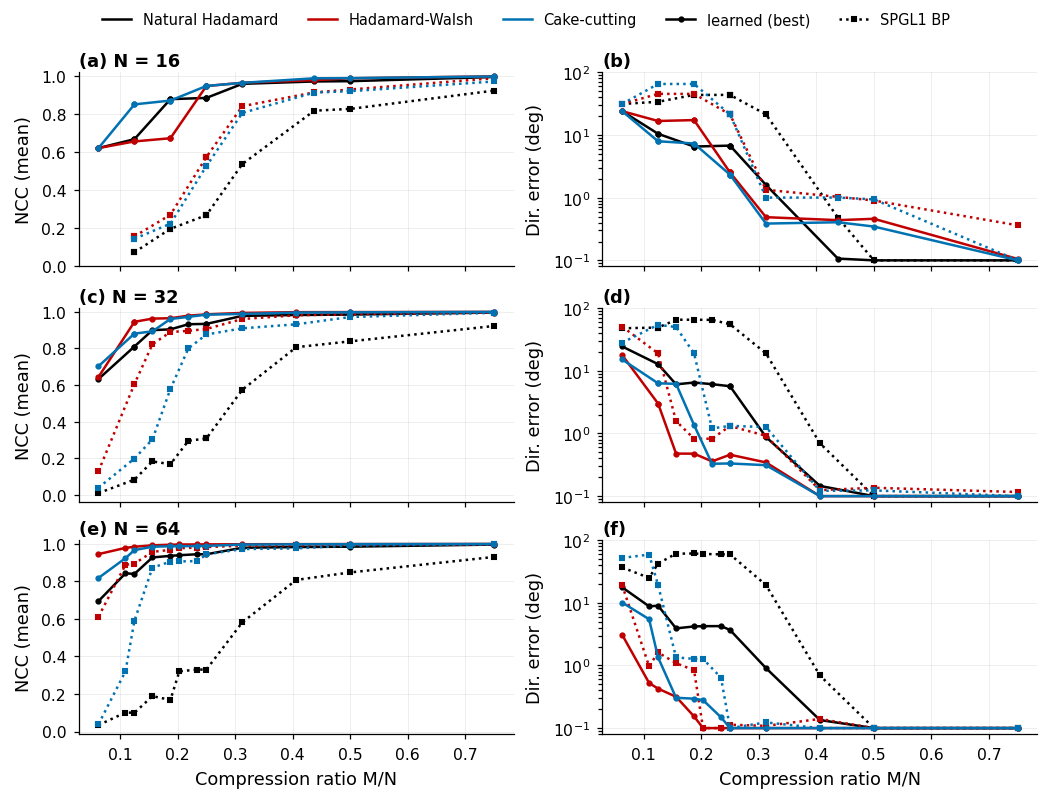

Median reconstruction time per profile (ms)
N                    16       32       64
method                                   
Learned (best)   0.0001   0.0003   0.0007
SPGL1 BP        11.0630  23.8269  41.6389

Mean NCC on test pixels at selected compression ratios
method                            Learned (best)  SPGL1 BP
N  ordering         requested_cr                          
16 Cake-cutting     0.125                  0.852     0.146
                    0.250                  0.949     0.527
                    0.500                  0.990     0.921
   Hadamard-Walsh   0.125                  0.657     0.158
                    0.250                  0.948     0.575
                    0.500                  0.989     0.930
   Natural Hadamard 0.125                  0.669     0.075
                    0.250                  0.886     0.269
                    0.500                  0.974     0.828
32 Cake-cutting     0.125                  0.881     0.200
                    0.25

In [21]:
# ⏱ 5–7 min (basis pursuit on DL_TEST_PIXELS_BP test pixels for every configuration)
DL_TEST_PIXELS_BP = 100       # test pixels per N on which SPGL1 BP is solved for the comparison (runtime!)

def direction_errors(Zp, Zr, n):
    """Axial differences of the peak axes for all pixels whose reference is anisotropic (A2 >= DIR_MIN_A2)."""
    a, _ = second_harmonic(Zp, n)
    b, an = second_harmonic(Zr, n)
    e = axial_difference(a, b)
    return e[an >= DIR_MIN_A2]

rows = []
for n in DL_NS:
    d = DLDATA[n]
    sub = np.random.default_rng(SEED).choice(len(d["Y_test"]), size=min(DL_TEST_PIXELS_BP, len(d["Y_test"])),
                                             replace=False)
    for name in DL_ORDERINGS:
        order = ORDERINGS[name](n)
        for cr in DL_CRS:
            M = m_from_cr(cr, n); idx = order[:M]
            best = DL_BEST[(n, name, cr)]
            t = time.perf_counter(); Zp = predict(best["model"], d["Y_test"][:, idx])
            t_learn = (time.perf_counter() - t) / len(Zp)
            t = time.perf_counter()
            Zb = np.array([cs_reconstruct(d["Y_test"][i], order, M, GAINS[n], "bp") for i in sub])
            t_bp = (time.perf_counter() - t) / len(sub)
            Zr_sub = d["Z_test"][sub]
            for method, Zrec, Zref, tt in [("Learned (best)", Zp[sub], Zr_sub, t_learn),
                                           ("SPGL1 BP", Zb, Zr_sub, t_bp)]:
                rows.append({"N": n, "ordering": name, "cr": M / n, "requested_cr": cr, "M": M, "method": method,
                             "ncc": nanmean_quiet(ncc_rows(Zrec, Zref)),
                             "rmse": float(np.mean(np.sqrt(np.mean((Zrec / Zref.max(1, keepdims=True)
                                                                    - Zref / Zref.max(1, keepdims=True)) ** 2, 1)))),
                             "direction_error": float(np.median(direction_errors(Zrec, Zref, n))),
                             "time_ms": 1e3 * tt, "pixels": len(Zref)})
            # learned model on all test pixels (larger statistics, reported in the table)
            rows.append({"N": n, "ordering": name, "cr": M / n, "requested_cr": cr, "M": M,
                         "method": "Learned (best), all test pixels",
                         "ncc": nanmean_quiet(ncc_rows(Zp, d["Z_test"])), "rmse": np.nan,
                         "direction_error": float(np.median(direction_errors(Zp, d["Z_test"], n))),
                         "time_ms": 1e3 * t_learn, "pixels": len(Zp)})
DL_DF = pd.DataFrame(rows)
save_table(DL_DF, "table12_learned_vs_bp", kind="article")

sh.plot_learned_vs_bp(DL_DF, DL_NS, DL_ORDERINGS)

SPEED = (DL_DF[DL_DF["method"].isin(["Learned (best)", "SPGL1 BP"])]
         .pivot_table(index="method", columns="N", values="time_ms", aggfunc="median").round(4))
print("Median reconstruction time per profile (ms)")
print(SPEED.to_string())
save_table(SPEED.reset_index(), "table13_learned_vs_bp_runtime_ms", kind="article")
print("\nMean NCC on test pixels at selected compression ratios")
print(DL_DF[DL_DF["requested_cr"].isin([0.125, 0.25, 0.5]) & (DL_DF["method"] != "Learned (best), all test pixels")]
      .pivot_table(index=["N", "ordering", "requested_cr"], columns="method", values="ncc").round(3).to_string())

**Discussion: closed form vs. Adam.** \
The first figure shows, for the Walsh ordering, the best validation NCC of each training source and method. Adam is trained only for the training source that the closed form selected; a curve of a source therefore appears for Adam only at the compression ratios where that source was selected (e.g. the canonical source only at the lowest CR for $N = 16$). For most configurations, the Adam curve (dashed) is close to the closed-form curve (solid), although some Adam fits perform worse. The validation results quantify this difference. Adam is selected for 21 of the 108 configurations in the saved run; in those cases, its validation score is slightly better than the tested ridge fits. The differences in validation NCC are in the third decimal. The training curves (second diagnostic figure) show that Adam converges within a few tens of epochs once the inputs are standardised. 

The training source matters more than the method. Training on measured Hadamard pairs is selected in almost all configurations: the inputs and targets contain the real noise and the real treatment of segment 0, whereas the canonical source relies on a simulated forward model and on canonical profiles with a different offset ([Section 1](#scrollTo=b243d8fd)).

**Discussion: learned reconstruction vs. basis pursuit.** \
The learned linear reconstruction is evaluated on measured Hadamard coefficients from held-out test pixels in the same specimen. At low compression ratios it is much better than basis pursuit: for $N = 32$ and the Walsh ordering the mean NCC is 0.95 vs. 0.61 at $\mathrm{CR} = 0.125$ and 0.99 vs. 0.91 at $\mathrm{CR} = 0.25$; at $\mathrm{CR} = 0.5$ both reach 0.99. Basis pursuit has too few measurements to identify the sparse support, while the learned map has absorbed the typical shape of SLI profiles from the training pixels. The learned model also makes the natural and cake-cutting orderings usable at low CR, because it learns which information each set of rows carries.

The reconstruction time of the learned model is a single matrix-vector product, about 0.1–0.6 µs per profile compared with 8–28 ms for SPGL1, i.e. about five orders of magnitude faster. The price is that a model is needed for every combination of $N$, ordering and compression ratio, and that performance on other samples or optical setups has not been established.

*Note on the per-pixel evaluation:* the method comparison uses the same 100 held-out test pixels for both methods. The additional learned-only results use all 3,492 held-out test pixels. These are single binned pixels, not ROI averages, and are therefore noisier than the profiles used in [Sections 3](#scrollTo=03d3a406) and [4](#scrollTo=61b987f3).

## 7. Application: direction maps from compressed data

The next cell computes maps of the dominant scattering axis $\theta$ (hue) weighted by the anisotropy $A_2$ (brightness) from (a) the canonical acquisition, (b) the full Hadamard acquisition, (c) Hadamard–Walsh CS with SPGL1 basis pursuit and (d) the selected learned linear reconstruction, the last two at the same compression ratio. The lower row shows the angular deviation of each map from the full Hadamard map.

**Definition of $\Delta$.** For every sample pixel, $\Delta$ is the axial difference between the peak axis of the respective map and that of the full Hadamard map, folded to $[0°, 90°]$. Pixels whose reference profile is almost isotropic ($A_2 < $ `DIR_MIN_A2`) are excluded, because their axis is not defined. The value printed in each panel is the median of $\Delta$ over the remaining sample pixels. For the canonical map, $\Delta$ describes the disagreement between two independent acquisitions. This provides a useful experimental comparison, but is not an absolute measure of orientation accuracy.

Basis pursuit is solved for every sample pixel of the binned image, which takes a few minutes; the learned reconstruction is a single matrix multiplication for the whole image.


[Section 7.1](#scrollTo=273feac5) then measures the reconstruction times of both approaches for this map and extrapolates them to the full-resolution image.

10561 pixels: basis pursuit 4.7 min, learned 7 ms
Learned model: source = hadamard, method = closed form, validation NCC = 0.985
                    map  median Delta (deg)  mean Delta (deg)  fraction Delta < 5 deg  pixels
              Canonical               1.583             1.916                   0.960   10542
Walsh + SPGL1 BP, M = 8               1.366             1.553                   0.995   10542
 Walsh + learned, M = 8               0.483             0.616                   1.000   10542


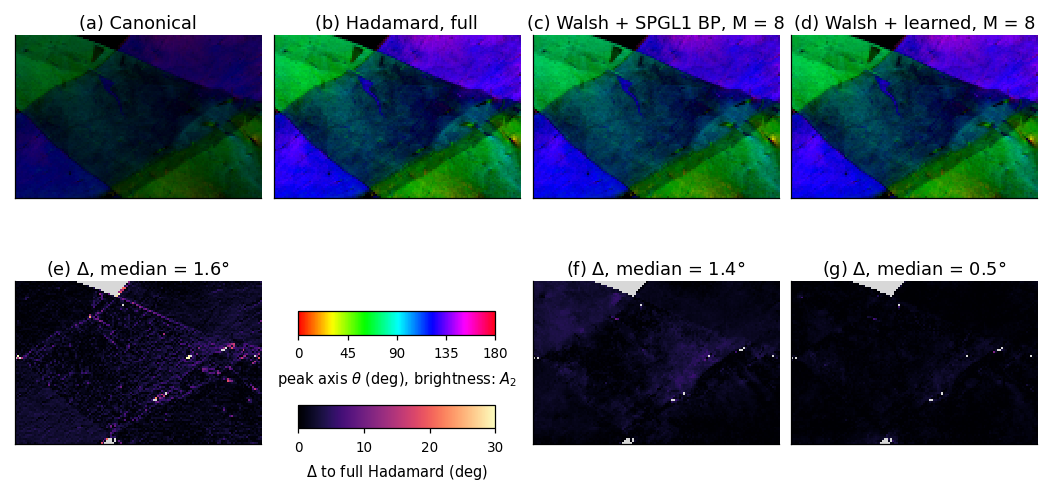

[cell run time: 4.7 min]


In [22]:
# ⏱ 3–5 min (basis pursuit for every tissue pixel of the binned image)
RUN_MAPS = True
MAP_N = 32 if 32 in DL_NS else DL_NS[0]
MAP_CR = 0.25
MAP_ORDERING = "Hadamard-Walsh"
DELTA_MAX = 30.0               # colour scale of the deviation maps (deg)

if RUN_MAPS:
    n = MAP_N
    d = DLDATA[n]
    mask = d["valid"]
    order = ORDERINGS[MAP_ORDERING](n)
    cr_key = min(DL_CRS, key=lambda c: abs(c - MAP_CR))
    M = m_from_cr(cr_key, n); idx = order[:M]
    profiles = {"Canonical": d["C_map"], "Hadamard, full": d["Z_map"]}

    # compressed reconstruction with SPGL1 basis pursuit, pixel by pixel
    bp_map = np.zeros_like(d["Z_map"])
    t = time.perf_counter()
    for (yy, xx) in np.argwhere(mask):
        bp_map[yy, xx] = cs_reconstruct(d["Y_map"][yy, xx], order, M, GAINS[n], "bp")
    T_BP_MAP = time.perf_counter() - t
    profiles[f"Walsh + SPGL1 BP, M = {M}"] = bp_map

    # compressed reconstruction with the selected learned model: one matrix product for all pixels
    best = DL_BEST[(n, MAP_ORDERING, cr_key)]
    learned = np.zeros_like(d["Z_map"])
    t = time.perf_counter()
    learned[mask] = predict(best["model"], d["Y_map"][mask][:, idx])
    T_LEARN_MAP = time.perf_counter() - t
    profiles[f"Walsh + learned, M = {M}"] = learned
    print(f"{mask.sum()} pixels: basis pursuit {format_duration(T_BP_MAP)}, learned {format_duration(T_LEARN_MAP)}")
    print(f"Learned model: source = {best['source']}, method = {best['method']}, validation NCC = {best['val_ncc']:.3f}")

    # peak axis and anisotropy of every map; deviation Delta from the full Hadamard map
    maps = {name: second_harmonic(prof, n) for name, prof in profiles.items()}
    ref_axis, ref_an = maps["Hadamard, full"]
    eval_mask = mask & (ref_an >= DIR_MIN_A2)
    rows, deltas = [], {}
    for name, (a, _) in maps.items():
        if name != "Hadamard, full":
            deltas[name] = np.where(eval_mask, axial_difference(a, ref_axis), np.nan)
            rows.append({"map": name, "median Delta (deg)": np.nanmedian(deltas[name]),
                         "mean Delta (deg)": np.nanmean(deltas[name]),
                         "fraction Delta < 5 deg": np.nanmean(deltas[name][eval_mask] < 5),
                         "pixels": int(eval_mask.sum())})
    MAP_DF = pd.DataFrame(rows).round(3)
    print(MAP_DF.to_string(index=False))
    save_table(MAP_DF, "table14_direction_maps", kind="article")
    np.savez_compressed(DIAG_DIR / "tables" / "diag06_direction_maps.npz",
                        **{re.sub(r"\W+", "_", k): v for k, v in profiles.items()}, mask=mask)
    sh.plot_direction_maps(maps, deltas, mask, vmax=np.nanpercentile(ref_an[mask], 99), delta_max=DELTA_MAX)

**Discussion.** All four maps show the same structure: the two strands with clearly different peak axes and the crossing region with a lower anisotropy and an intermediate axis. The deviation maps and the table quantify the agreement with the full Hadamard map (values from the saved run):

* **Canonical vs. full Hadamard:** median deviation of about 1.6°. This gives the observed disagreement between two independent acquisitions of the section.
* **Walsh + SPGL1 BP at $\mathrm{CR} = 0.25$** (8 of 32 patterns): about 1.4°, and 99.5 % of the pixels deviate by less than 5°.
* **Walsh + learned model at $\mathrm{CR} = 0.25$:** about 0.5°, all pixels below 5°.

The compressed maps deviate *less* than the canonical map. This does not mean that they are more accurate than an independent measurement: the compressed reconstructions use a subset of the same acquisition as the reference, so they share its noise and calibration, whereas the canonical map does not. $\Delta$ therefore measures how much information is lost by the compression; with both reconstruction methods this loss is below the difference between two independent measurements. The learned model deviates least because its training targets were the full Hadamard profiles. The whole-section learned map includes training and validation pixels; only the held-out test results in [Section 6](#scrollTo=825cdb22) quantify within-specimen performance on unseen pixels. The remaining map deviations are concentrated at region boundaries and in weakly anisotropic pixels, where the axis is poorly defined even in the reference.

### 7.1 Reconstruction time for a full SLI image

The maps above are computed on the binned image ($43 \times 43$ camera pixels per map pixel, about $10^4$ profiles). A full-resolution SLI image of this field of view has $3648 \times 5472 \approx 2\times10^7$ pixels, i.e. about 1850 times more profiles. The next cell measures the reconstruction time per profile of both methods and extrapolates it to the full image:

* **SPGL1 basis pursuit:** solves one optimisation problem per pixel, so the time scales linearly with the number of pixels. The calculation uses the time measured for the map above. Pixels are independent, so the work can be distributed over CPU cores; the table gives the time for one core and for all cores of the current machine (ideal parallel speed-up).
* **Learned model:** one matrix product $(P \times M)(M \times N)$. To measure the throughput at a realistic problem size, the model is applied to $10^6$ profiles (in blocks, to limit the memory) and the result is extrapolated.

Reading the raw frames and computing the peak axes are not included as they are the same for both methods.

In [23]:
# ⏱ ~10 s
if RUN_MAPS:
    n_map = int(mask.sum())
    tissue_fraction = TISSUE_MASK.mean()
    full_all = IMG_H * IMG_W                         # all camera pixels of the field of view
    full_tissue = tissue_fraction * full_all         # pixels inside the tissue mask
    cores = os.cpu_count() or 1

    # throughput of the learned model on 10^6 profiles (measured coefficients of the map, repeated)
    P_TEST, BLOCK = 1_000_000, 250_000
    y_src = d["Y_map"][mask][:, idx]
    y_big = y_src[np.arange(P_TEST) % len(y_src)]
    t = time.perf_counter()
    for i in range(0, P_TEST, BLOCK):
        predict(best["model"], y_big[i:i + BLOCK])
    t_learn_px = (time.perf_counter() - t) / P_TEST
    t_bp_px = T_BP_MAP / n_map

    rows = []
    for method, t_px, parallel in [("SPGL1 BP", t_bp_px, True), ("Learned (best)", t_learn_px, False)]:
        rows.append({"method": method, "N": n, "M": M,
                     "time per profile": format_duration(t_px),
                     f"binned map ({n_map} px)": format_duration(t_px * n_map),
                     f"full image, tissue ({full_tissue / 1e6:.1f} Mpx), 1 core": format_duration(t_px * full_tissue),
                     f"full image, tissue, {cores} cores": format_duration(t_px * full_tissue / cores) if parallel else "-",
                     f"full image, all pixels ({full_all / 1e6:.1f} Mpx), 1 core": format_duration(t_px * full_all),
                     "seconds per profile": t_px})
    RUNTIME_DF = pd.DataFrame(rows)
    print(RUNTIME_DF.drop(columns="seconds per profile").to_string(index=False))
    print(f"\nSpeed-up of the learned model: {t_bp_px / t_learn_px:.1e}")
    save_table(RUNTIME_DF, "table15_runtime_full_image", kind="article")

        method  N  M time per profile binned map (10561 px) full image, tissue (19.8 Mpx), 1 core full image, tissue, 2 cores full image, all pixels (20.0 Mpx), 1 core
      SPGL1 BP 32  8            27 ms               4.7 min                                 6.1 d                       3.0 d                                     6.1 d
Learned (best) 32  8           456 ns                  5 ms                                 9.0 s                           -                                     9.1 s

Speed-up of the learned model: 5.8e+04


**Discussion.** Basis pursuit needs about 27 ms per profile for $N = 32$ and $M = 8$ in the saved run (4.7 minutes for the binned map). Extrapolated to about $2\times10^7$ full-resolution pixels, this corresponds to roughly six days on one CPU core; parallel processing can reduce the time. Such reconstruction times would cancel the gain in acquisition time that compressive sensing offers. The learned linear model needs well below one microsecond per profile, giving an extrapolated full-resolution reconstruction time of about nine seconds on the tested CPU. Model training ([Section 6](#scrollTo=825cdb22)) is performed once per measurement configuration.

The extrapolation assumes that the time per profile does not depend on the pixel content, which is a good approximation for the learned model (a fixed number of operations) and an average for basis pursuit, whose number of iterations varies between pixels. The numerical speed-up depends on the hardware and implementation; these estimates refer to the CPU methods used here.

## 8. Summary and exercises

**What the notebook shows**
1. With the full basis, canonical and Hadamard SLI measure the same line profiles. The differences originate from constant frame offsets: in the binary Hadamard scheme a constant frame offset appears in the first reconstructed segment, in the canonical basis it is spread over all segments ([Sec. 1](#scrollTo=b243d8fd)).
2. SLI line profiles are compressible in the DCT basis, and the number of significant coefficients is set by the angular structure of the profile, not by $N$. The Hadamard/DCT pair is maximally coherent, so the ordering of the patterns decides which angular frequencies are measured first ([Sec. 2](#scrollTo=0c4e2bc8)).
3. With $\Psi$ and the solver fixed, the Hadamard–Walsh ordering requires the fewest measurements for these profiles; the required number of measurements is almost independent of $N$, so the compression ratio decreases for larger $N$ ([Sec. 3](#scrollTo=03d3a406)).
4. With ordering and $\Psi$ fixed, sparsity-promoting solvers with a data constraint (BP, BPDN) outperform least-squares-like solvers; their runtime is the practical limitation ([Sec. 4](#scrollTo=61b987f3)).
5. The noise simulation separates shot-noise and read-noise limited regimes and shows when multiplexed illumination and denoising solvers pay off ([Sec. 5](#scrollTo=0a48ce9b), diagnostic).
6. A linear reconstruction, trained and selected on measured data of the same instrument, outperforms basis pursuit at low compression ratios on held-out pixels from the same specimen and is several orders of magnitude faster. The full-section maps agree well with the full Hadamard reference using one quarter of the patterns; full-resolution runtimes are extrapolated ([Secs. 6](#scrollTo=825cdb22)–[7](#scrollTo=c7fbcbf5)).

**Results.** Figures and tables for the manuscript are saved in `OUTPUT_DIR/article`, and checks and intermediate results in `OUTPUT_DIR/diagnostics` (see the last cell for the list of files). The helper functions for data handling, plotting and saving are in `sli_helpers.py`.

**Exercises**
* Change `REF_KEY` to `"z_can"` and repeat [Sec. 3](#scrollTo=03d3a406). How much of the remaining error is due to the measurement itself?
* Set `CALIBRATION_MODE = "first_segment"` or `"none"`. Which orderings and which learned models are most sensitive to a wrong treatment of segment 0, and why?
* Replace the DCT by another sparsifying basis (e.g. the FFT of the periodic profile) and compare the plateau CR.
* Restrict the training source of [Section 6](#scrollTo=825cdb22) to `"canonical"` and vary `DL_NOISE_GRID`. When does a model trained on canonical data generalise to compressed Hadamard measurements?
* Train the learned model on one half of the section and test it on the other half, or on a different sample. How strongly does it depend on the training data?

In [24]:
# ⏱ < 5 s
# ----------------------------------------------------------------------------- run settings and list of results
settings = {k: (str(v) if isinstance(v, Path) else v) for k, v in {
    "DATA_ROOT": DATA_ROOT, "NS": NS, "SKIP_FIRST_FRAME": SKIP_FIRST_FRAME, "ANGLE_CONVENTION": ANGLE_CONVENTION,
    "PREVIEW_BIN": PREVIEW_BIN, "CALIBRATION_MODE": CALIBRATION_MODE, "COMPRESSION_RATIOS": COMPRESSION_RATIOS,
    "DIR_MIN_A2": DIR_MIN_A2, "ROIS": [list(map(int, r)) for r in ROIS], "ROI_NAMES": ROI_NAMES,
    "TISSUE_PERCENTILE": TISSUE_PERCENTILE, "MAP_N": MAP_N, "MAP_CR": MAP_CR, "ISTA_LAMBDA": ISTA_LAMBDA, "BPDN_SIGMA_FRACTION": BPDN_SIGMA_FRACTION,
    "LASSO_TAU_FRACTION": LASSO_TAU_FRACTION, "DL_RIDGE_GRID": DL_RIDGE_GRID, "DL_NOISE_GRID": DL_NOISE_GRID,
    "DL_LR": DL_LR, "DL_MAX_EPOCHS": DL_MAX_EPOCHS, "DL_PATIENCE": DL_PATIENCE, "DL_BATCH": DL_BATCH,
    "DL_BLOCK": DL_BLOCK, "SEED": SEED, "QUICK_DATA": QUICK}.items()}
with open(OUTPUT_DIR / "run_settings.json", "w") as f:
    json.dump(settings, f, indent=2)

for kind, base in [("article", ARTICLE_DIR), ("diagnostics", DIAG_DIR)]:
    print(f"\n{kind}:")
    for p in sorted(base.rglob("*")):
        if p.is_file() and p.suffix in (".png", ".csv", ".npz"):
            print("  ", p.relative_to(OUTPUT_DIR))


article:
   article/figures/fig01_overview_rois.png
   article/figures/fig02_roi_profiles.png
   article/figures/fig03_full_basis_sampling.png
   article/figures/fig04_dct_spectra.png
   article/figures/fig05_orderings.png
   article/figures/fig06_ordering_metrics.png
   article/figures/fig07_plateau_best_profiles.png
   article/figures/fig08a_reconstruction_grid_roi1.png
   article/figures/fig08b_reconstruction_grid_roi3.png
   article/figures/fig09_algorithm_metrics.png
   article/figures/fig10_learned_vs_bp.png
   article/figures/fig11_direction_maps.png
   article/tables/table01_rois.csv
   article/tables/table02_roi_properties.csv
   article/tables/table03_full_basis_agreement.csv
   article/tables/table04_sparsity.csv
   article/tables/table05_mutual_coherence.csv
   article/tables/table06_ordering_metrics_long.csv
   article/tables/table07_ordering_summary.csv
   article/tables/table08_plateau_best.csv
   article/tables/table09_plateau_vs_sparsity.csv
   article/tables/table10_